# Environment setup & graphical parameters

In [45]:
# Import packages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
import glob
from IPython.display import display, HTML
import gc

from scipy import stats

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from P7_functions import *

%pylab inline

pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 1000)

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/IPython/core/magics/pylab.py:162: UserWarning: pylab import has clobbered these variables: ['f']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


# Data loading

In [8]:
# Reading all csv file in the data folder
path = os.getcwd()
path += "/Data/*.csv"


for file in glob.glob(path):
    print(file)

/Users/franck/Documents/P7_Implementez_modele_scoring/Data/application_test.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/HomeCredit_columns_description.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/POS_CASH_balance.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/application_train_sample.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/credit_card_balance.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/installments_payments.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/application_train.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/bureau.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/previous_application.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/bureau_balance.csv
/Users/franck/Documents/P7_Implementez_modele_scoring/Data/sample_submission.csv



The above datatables are comming from the Kaggle Kernel: https://www.kaggle.com/c/home-credit-default-risk/data

They are structure that way: 

**application_{train|test}.csv**
* This is the main table, broken into two files for Train (with TARGET) and Test (without TARGET).
* Static data for all applications. One row represents one loan in our data sample.

**bureau.csv**
* All client's previous credits provided by other financial institutions that were reported to Credit Bureau (for clients who have a loan in our sample).
* For every loan in our sample, there are as many rows as number of credits the client had in Credit Bureau before the application date.

**bureau_balance.csv**
* Monthly balances of previous credits in Credit Bureau.
* This table has one row for each month of history of every previous credit reported to Credit Bureau – i.e the table has (#loans in sample * # of relative previous credits * # of months where we have some history observable for the previous credits) rows.

**POS_CASH_balance.csv**
* Monthly balance snapshots of previous POS (point of sales) and cash loans that the applicant had with Home Credit.
* This table has one row for each month of history of every previous credit in Home Credit (consumer credit and cash loans) related to loans in our sample – i.e. the table has (#loans in sample * # of relative previous credits * # of months in which we have some history observable for the previous credits) rows.

**credit_card_balance.csv**
* Monthly balance snapshots of previous credit cards that the applicant has with Home Credit.
* This table has one row for each month of history of every previous credit in Home Credit (consumer credit and cash loans) related to loans in our sample – i.e. the table has (#loans in sample * # of relative previous credit cards * # of months where we have some history observable for the previous credit card) rows.

**previous_application.csv**
* All previous applications for Home Credit loans of clients who have loans in our sample.
* There is one row for each previous application related to loans in our data sample.

**installments_payments.csv**
* Repayment history for the previously disbursed credits in Home Credit related to the loans in our sample.
* There is a) one row for every payment that was made plus b) one row each for missed payment.
* One row is equivalent to one payment of one installment OR one installment corresponding to one payment of one previous Home Credit credit related to loans in our sample.

**HomeCredit_columns_description.csv**
* This file contains descriptions for the columns in the various data files.


In [9]:
# Visualise each datatable 
for file in glob.glob(path):
    df = pd.read_csv(file,
                    low_memory=False,
                    verbose=False,
                    encoding='ISO-8859-1',
                    dtype={'Special': 'object'}
                    )
    print(file)
    print(df.shape)
    display(df.head())

/Users/franck/Documents/P7_Implementez_modele_scoring/Data/application_test.csv
(48744, 121)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,Unaccompanied,Working,Higher education,Married,House / apartment,0.018850,-19241,-2329,-5170.0,-812,NaN,1,1,0,1,0,1,NaN,2.0,2,2,TUESDAY,18,0,0,0,0,0,0,Kindergarten,0.752614,0.789654,0.159520,0.0660,0.0590,0.9732,NaN,NaN,NaN,0.1379,0.125,NaN,NaN,NaN,0.0505,NaN,NaN,0.0672,0.0612,0.9732,NaN,NaN,NaN,0.1379,0.125,NaN,NaN,NaN,0.0526,NaN,NaN,0.0666,0.0590,0.9732,NaN,NaN,NaN,0.1379,0.125,NaN,NaN,NaN,0.0514,NaN,NaN,NaN,block of flats,0.0392,"Stone, brick",No,0.0,0.0,0.0,0.0,-1740.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,0.035792,-18064,-4469,-9118.0,-1623,NaN,1,1,0,1,0,0,Low-skill Laborers,2.0,2,2,FRIDAY,9,0,0,0,0,0,0,Self-employed,0.564990,0.291656,0.432962,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,NaN,Working,Higher education,Married,House / apartment,0.019101,-20038,-4458,-2175.0,-3503,5.0,1,1,0,1,0,0,Drivers,2.0,2,2,MONDAY,14,0,0,0,0,0,0,Transport: type 3,NaN,0.699787,0.610991,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-856.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,Unaccompanied,Working,Secondary / secondary special,Married

/Users/franck/Documents/P7_Implementez_modele_scoring/Data/HomeCredit_columns_description.csv
(219, 5)


,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN


/Users/franck/Documents/P7_Implementez_modele_scoring/Data/POS_CASH_balance.csv
(10001358, 8)


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


/Users/franck/Documents/P7_Implementez_modele_scoring/Data/application_train_sample.csv
(48048, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,437476,0,Revolving loans,M,Y,Y,0,270000.0,135000.0,6750.0,135000.0,Unaccompanied,Commercial associate,Incomplete higher,Married,House / apartment,0.019101,-8885,-193,-3525.0,-1560,5.0,1,1,1,1,0,0,Sales staff,2.0,2,2,TUESDAY,17,1,1,0,1,1,0,Trade: type 2,0.325435,0.579329,0.286652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,0.0,6.0,0.0,-168.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,136803,0,Cash loans,F,N,Y,2,225000.0,472500.0,18436.5,472500.0,Unaccompanied,Commercial associate,Higher education,Married,House / apartment,0.032561,-11539,-1315,-921.0,-2515,NaN,1,1,0,1,0,0,Core staff,4.0,1,1,MONDAY,16,0,0,0,0,0,0,Trade: type 3,NaN,0.360583,0.321735,0.0995,0.1186,0.9985,0.9728,0.0235,0.0,0.1552,0.1458,0.1875,0.0877,0.0811,0.1222,0.0000,0.0000,0.0242,0.0327,0.9985,0.9739,0.0042,0.0,0.0345,0.1250,0.1667,0.0275,0.0211,0.0299,0.0000,0.0000,0.1004,0.1186,0.9985,0.9732,0.0236,0.0,0.1552,0.1458,0.1875,0.0893,0.0825,0.1244,0.0000,0.0000,reg oper account,block of flats,0.2301,Monolithic,No,0.0,0.0,0.0,0.0,-76.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,1.0,0.0
2,377527,0,Cash loans,F,Y,Y,0,135000.0,254700.0,25321.5,225000.0,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,0.011657,-22637,-4642,-12229.0,-3983,4.0,1,1,0,1,0,0,Laborers,2.0,1,1,WEDNESDAY,18,0,0,0,0,1,1,Self-employed,NaN,0.648081,0.805020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-2963.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,

/Users/franck/Documents/P7_Implementez_modele_scoring/Data/credit_card_balance.csv
(3840312, 23)


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_CURRENT,AMT_PAYMENT_TOTAL_CURRENT,AMT_RECEIVABLE_PRINCIPAL,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,1800.0,1800.0,0.000,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,2250.0,2250.0,60175.080,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,2250.0,2250.0,26926.425,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,11925.0,11925.0,224949.285,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,27000.0,27000.0,443044.395,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


/Users/franck/Documents/P7_Implementez_modele_scoring/Data/installments_payments.csv
(13605401, 8)


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


/Users/franck/Documents/P7_Implementez_modele_scoring/Data/application_train.csv
(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

/Users/franck/Documents/P7_Implementez_modele_scoring/Data/bureau.csv
(1716428, 17)


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


/Users/franck/Documents/P7_Implementez_modele_scoring/Data/previous_application.csv
(1670214, 37)


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,NAME_CASH_LOAN_PURPOSE,NAME_CONTRACT_STATUS,DAYS_DECISION,NAME_PAYMENT_TYPE,CODE_REJECT_REASON,NAME_TYPE_SUITE,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,SELLERPLACE_AREA,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,Y,1,0.0,0.182832,0.867336,XAP,Approved,-73,Cash through the bank,XAP,NaN,Repeater,Mobile,POS,XNA,Country-wide,35,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-164,XNA,XAP,Unaccompanied,Repeater,XNA,Cash,x-sell,Contact center,-1,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-301,Cash through the bank,XAP,"Spouse, partner",Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,Y,1,NaN,NaN,NaN,XNA,Approved,-512,Cash through the bank,XAP,NaN,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,Y,1,NaN,NaN,NaN,Repairs,Refused,-781,Cash through the bank,HC,NaN,Repeater,XNA,Cash,walk-in,Credit and cash offices,-1,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


/Users/franck/Documents/P7_Implementez_modele_scoring/Data/bureau_balance.csv
(27299925, 3)


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


/Users/franck/Documents/P7_Implementez_modele_scoring/Data/sample_submission.csv
(48744, 2)


,SK_ID_CURR,TARGET
0,100001,0.5
1,100005,0.5
2,100013,0.5
3,100028,0.5
4,100038,0.5


All the datatable have been merge as followed

![Merge_chart](data/home_credit.png)

For this project, we are going to use only application_train which for the exploratory analysis and the modelisation 

In [10]:
# Follow all the variable description
f = 'data/HomeCredit_columns_description.csv'
DESCRIPTOR = pd.read_csv(f, encoding='ISO-8859-1')
display(HTML(DESCRIPTOR.to_html()))

,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,"Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)",NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,8,application_{train|test}.csv,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,9,application_{train|test}.csv,CNT_CHILDREN,Number of children the client has,NaN
7,10,application_{train|test}.csv,AMT_INCOME_TOTAL,Income of the client,NaN
8,11,application_{train|test}.csv,AMT_CREDIT,Credit amount of the loan,NaN
9,12,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,NaN


As suggested we are going to use a Kaggle Kernel to preprocess and merge all the table of the data base. The kernel is: https://www.kaggle.com/jsaguiar/lightgbm-with-simple-features
We are going to clean application_train.csv manually. Then all other dataset are going to be aggregate and merge to this dataset. The aggregation part and the merging are directly taken from the kernel, however we are going to analysis those new feature and remove correlated features and evaluate which features seems to be linked to TARGET with ANOVA.


We are just not going to use the table application_test.csv are the Target are missing. This table is then not usefull for us. To train the model we simply are going to separate the final dataset into au train set and a test set. 

# Exploratory Descriptive Analysis

## Application Train

In [11]:
data = pd.read_csv('data/application_train.csv',
                 low_memory=False,
                 verbose=False,
                 encoding='ISO-8859-1',
                 dtype={'Special': 'object'}
                )

In [12]:
data.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

### Objective: 
* Better undertant the data
* Develop a first modelisation strategy



### Checklist 

#### Shape analysis: 
* **Target variable**: TARGET
* **Row and column**: 307511, 122
* **Type of varibale**: numerical: 105, categorical: 16
* **Missing values analysis**: 24.39 % of total NaN. The minimum filling rate is 30% 


#### Meaning analysis: 
* **Target visualisation**:
    * 8% of client with payment difficulties
* **Features signification**: (See table above)
    * Some variable are triple AVG_, MODE_, MEDI_
    * FLAG variable a binary variable [0, 1] -> categorical variable
    * Continous features are not normaly distributed, skewed, 
    *Lot of variable a already normalized -> Normalisation for modeling
    * FLAG_MOBILE -> 100% YES; FLAG_CONT_MOBILE ~100% YES, FLAG_DOCUMENT -> almost all 0 except for FLAG_DOCUMENT_3
    * SK_ID_CURR -> to remove for model
    * DAYS_BIRTH, DAYS_EMPLOYED, DAYS_ID_PUBLISH -> continous variable
* **Target/features realtion**: 
    * target/continous: EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3 seems dependant of TARGET -> hypothesis checked with ANOVA 
            (we have no infos on their signification...)
    * target/discrete: No real dependency between target and discrete features -> confirm with Cramer's V score

#### Deeper analysis: 
* Features/features analysis: AVG_, MODE_, MEDI_ of each variable are strongly correlated -> we could keep only on a each


### Shape Analysis

In [13]:
df = data.copy()

In [14]:
df.shape

(307511, 122)

float64    65
int64      41
object     16
dtype: int64


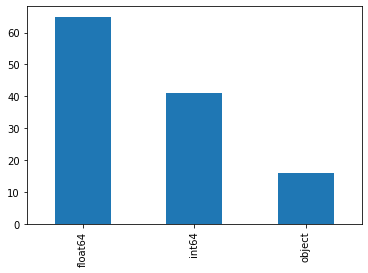

In [15]:
# Count features type
print(df.dtypes.value_counts())

#Show feautres type count
df.dtypes.value_counts().plot.bar()
plt.show()

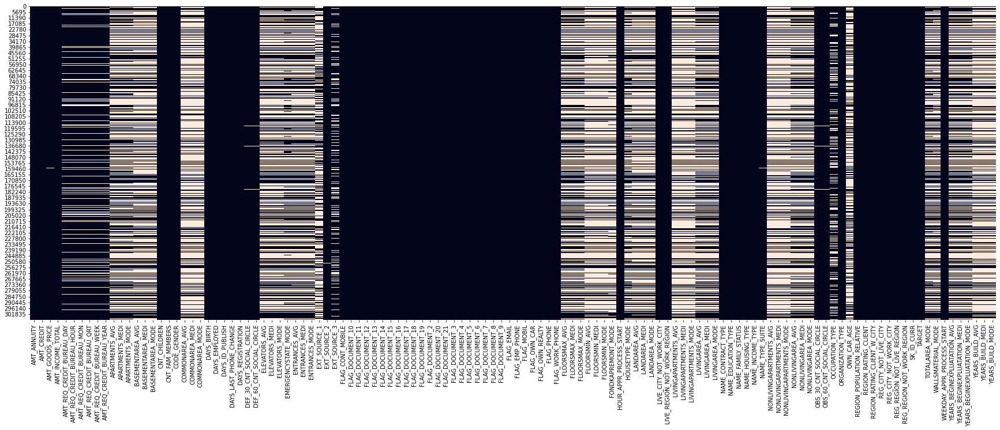

In [16]:
plt.figure(figsize=(30,10))
sns.heatmap(df[sorted(df.columns)].isna(), cbar=False)
plt.show()

In [17]:
# Calculated the total percentage of missing values

print(df.isna().sum().sum()/(df.shape[0]*df.shape[1])*100)

24.39594190712943


In [18]:
# Analysis of each features filling rated
display(filling_factor(df.select_dtypes('float')))
display(filling_factor(df.select_dtypes('int')))
display(filling_factor(df.select_dtypes('object')))

,column_name,missing_count,filling_factor
0,COMMONAREA_MEDI,214865,30.127703
1,COMMONAREA_MODE,214865,30.127703
2,COMMONAREA_AVG,214865,30.127703
3,NONLIVINGAPARTMENTS_AVG,213514,30.567037
4,NONLIVINGAPARTMENTS_MEDI,213514,30.567037
5,NONLIVINGAPARTMENTS_MODE,213514,30.567037
6,LIVINGAPARTMENTS_AVG,210199,31.645047
7,LIVINGAPARTMENTS_MODE,210199,31.645047
8,LIVINGAPARTMENTS_MEDI,210199,31.645047
9,FLOORSMIN_MODE,208642,32.151370


,column_name,missing_count,filling_factor
0,SK_ID_CURR,0,100.0
1,FLAG_DOCUMENT_3,0,100.0
2,FLAG_DOCUMENT_4,0,100.0
3,FLAG_DOCUMENT_5,0,100.0
4,FLAG_DOCUMENT_6,0,100.0
5,FLAG_DOCUMENT_7,0,100.0
6,FLAG_DOCUMENT_8,0,100.0
7,FLAG_DOCUMENT_9,0,100.0
8,FLAG_DOCUMENT_10,0,100.0
9,FLAG_DOCUMENT_11,0,100.0


,column_name,missing_count,filling_factor
0,FONDKAPREMONT_MODE,210295,31.613828
1,WALLSMATERIAL_MODE,156341,49.159217
2,HOUSETYPE_MODE,154297,49.823909
3,EMERGENCYSTATE_MODE,145755,52.601696
4,OCCUPATION_TYPE,96391,68.654455
5,NAME_TYPE_SUITE,1292,99.579852
6,NAME_CONTRACT_TYPE,0,100.000000
7,CODE_GENDER,0,100.000000
8,FLAG_OWN_CAR,0,100.000000
9,FLAG_OWN_REALTY,0,100.000000


In [19]:
# Column by column analysis
for column in df.columns:
    if df[column].nunique() < 20:
        print('Column {}, Type: {}, unique value :\n{}\n'.format(column, df[column].dtypes, df[column].unique()))
    else:
        print('Column {}, Type: {}, {} unique value'.format(column, df[column].dtypes, df[column].nunique()))
    print('----------')

Column SK_ID_CURR, Type: int64, 307511 unique value
----------
Column TARGET, Type: int64, unique value :
[1 0]

----------
Column NAME_CONTRACT_TYPE, Type: object, unique value :
['Cash loans' 'Revolving loans']

----------
Column CODE_GENDER, Type: object, unique value :
['M' 'F' 'XNA']

----------
Column FLAG_OWN_CAR, Type: object, unique value :
['N' 'Y']

----------
Column FLAG_OWN_REALTY, Type: object, unique value :
['Y' 'N']

----------
Column CNT_CHILDREN, Type: int64, unique value :
[ 0  1  2  3  4  7  5  6  8  9 11 12 10 19 14]

----------
Column AMT_INCOME_TOTAL, Type: float64, 2548 unique value
----------
Column AMT_CREDIT, Type: float64, 5603 unique value
----------
Column AMT_ANNUITY, Type: float64, 13672 unique value
----------
Column AMT_GOODS_PRICE, Type: float64, 1002 unique value
----------
Column NAME_TYPE_SUITE, Type: object, unique value :
['Unaccompanied' 'Family' 'Spouse, partner' 'Children' 'Other_A' nan
 'Other_B' 'Group of people']

----------
Column NAME_IN

#### Target Anaylsis 

In [20]:
# Evaluation of target repartition 

# Target variable (1 - client with payment difficulties: 
# he/she had late payment more than X days on at least one of the first Y 
# installments of the loan in our sample, 0 - all other cases)

df['TARGET'].value_counts(normalize=True)

0    0.919271
1    0.080729
Name: TARGET, dtype: float64

### Univariate anaylsis
#### Continous variable

In [21]:
# Creation a contious variable list
num_col = df.select_dtypes(include=np.number).columns.to_list()
num_col.remove('TARGET')

len(num_col)

105

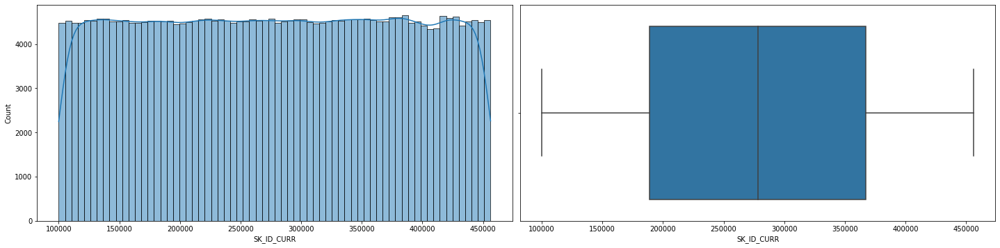

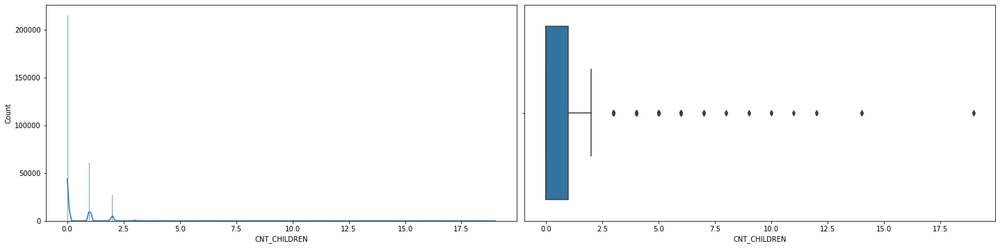

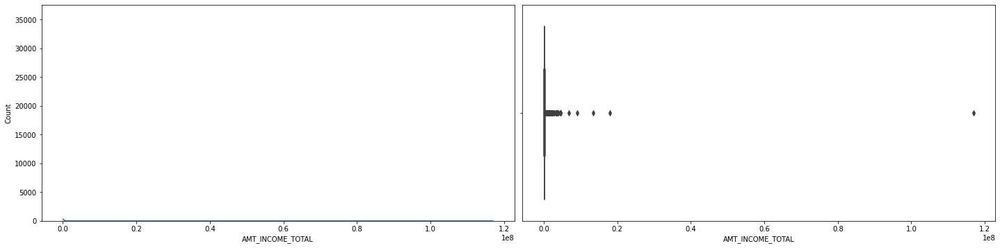

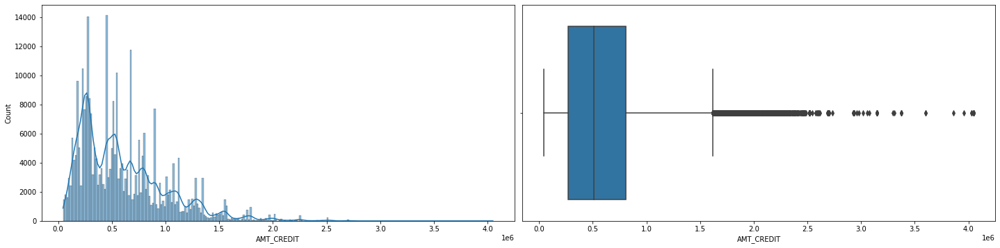

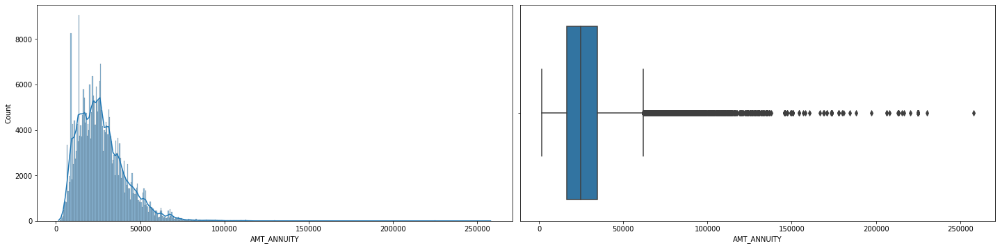

...

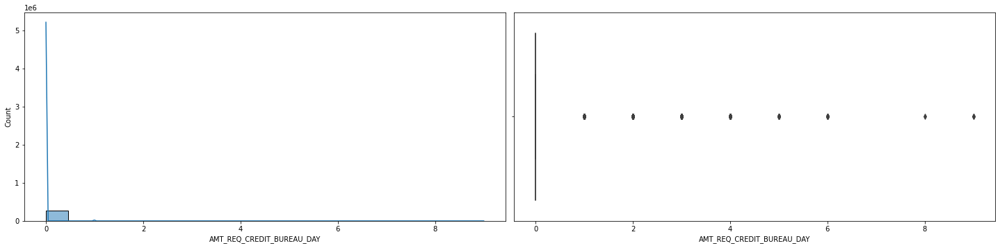

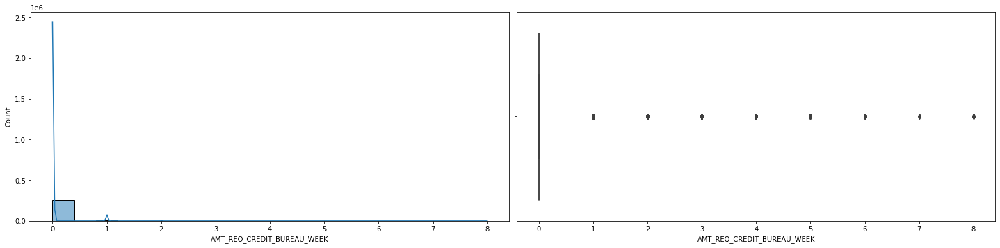

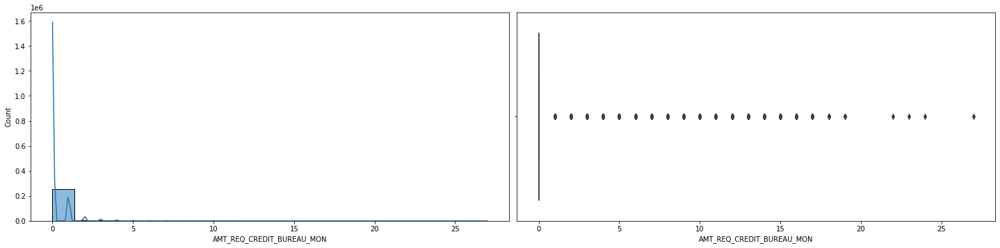

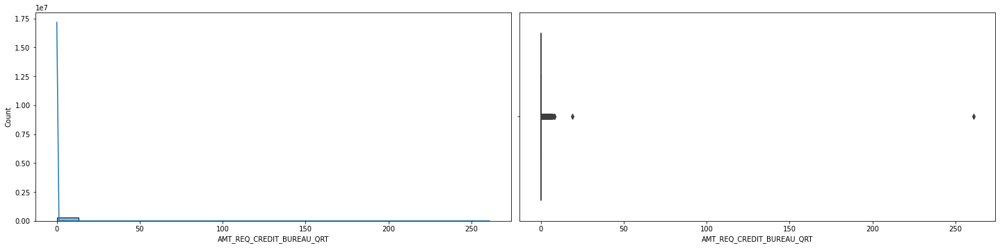

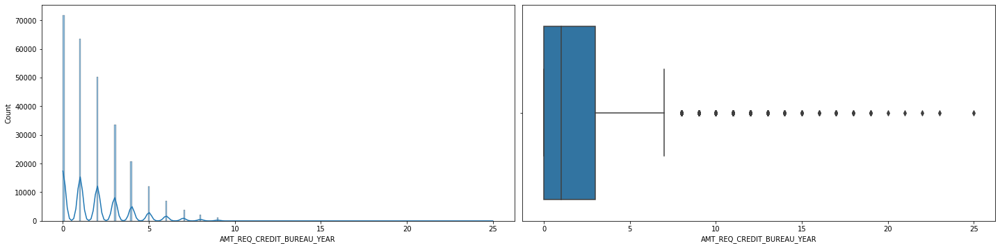

In [22]:
# Visualisation of continous variable 
EDA_continous(df[num_col])

#### Categorical variable 

In [23]:
# Creation of categorical variable list
cat_col = df.select_dtypes(exclude=np.number).columns.to_list()
len(cat_col)

16

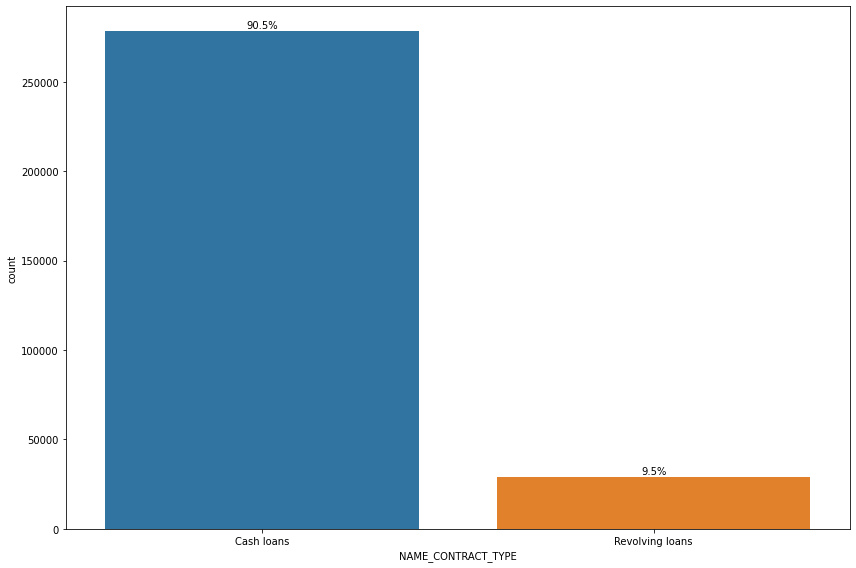

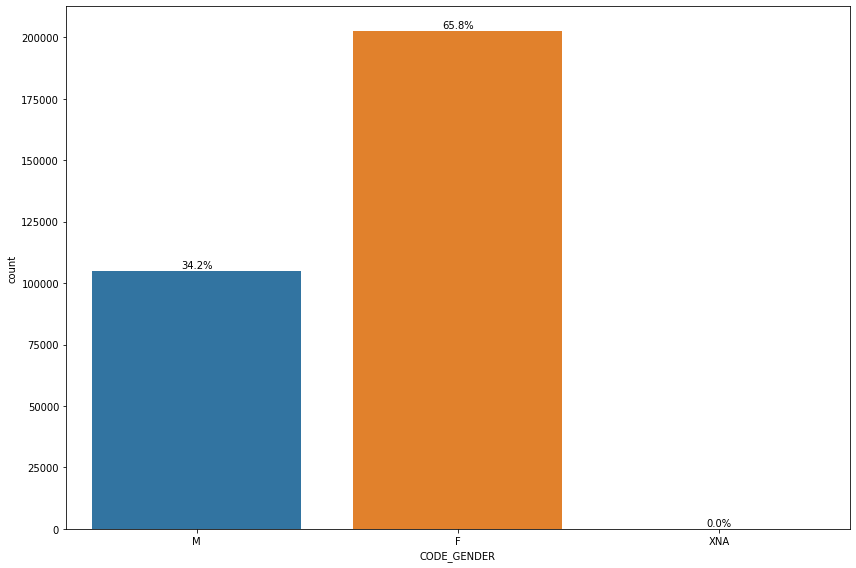

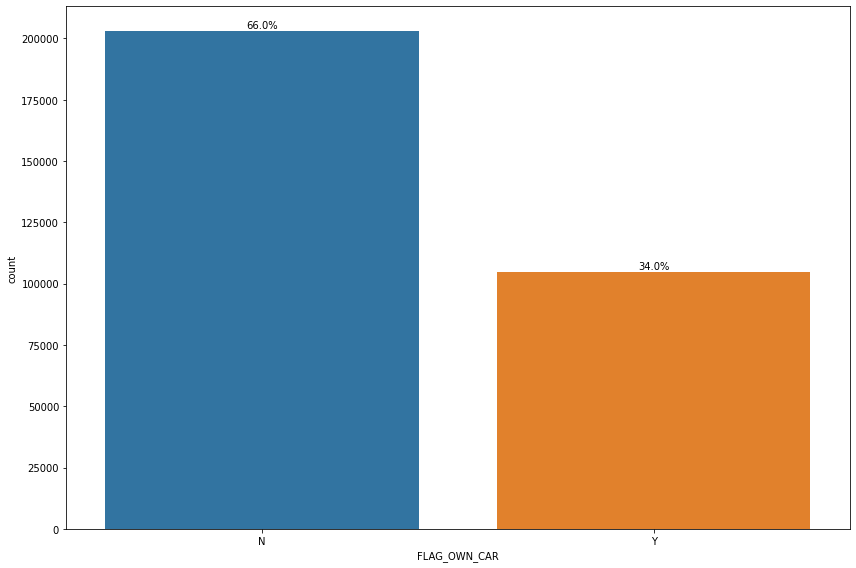

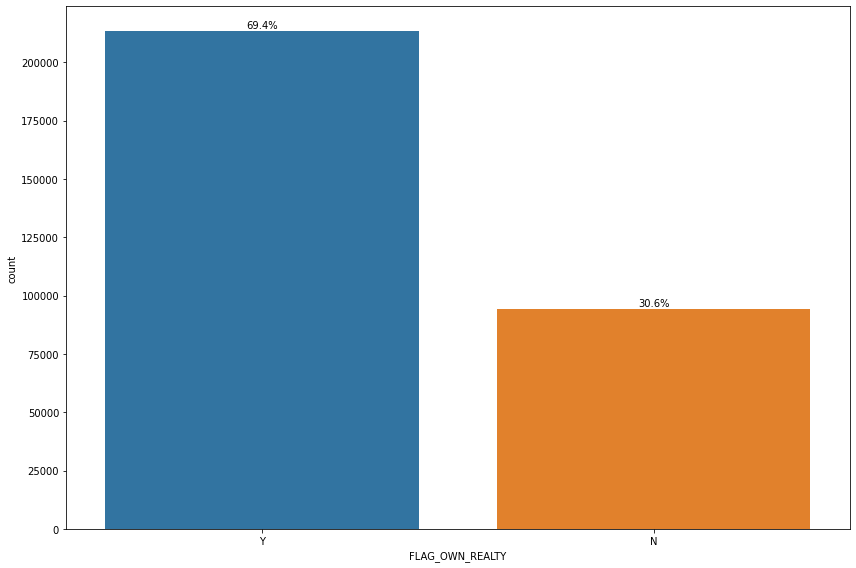

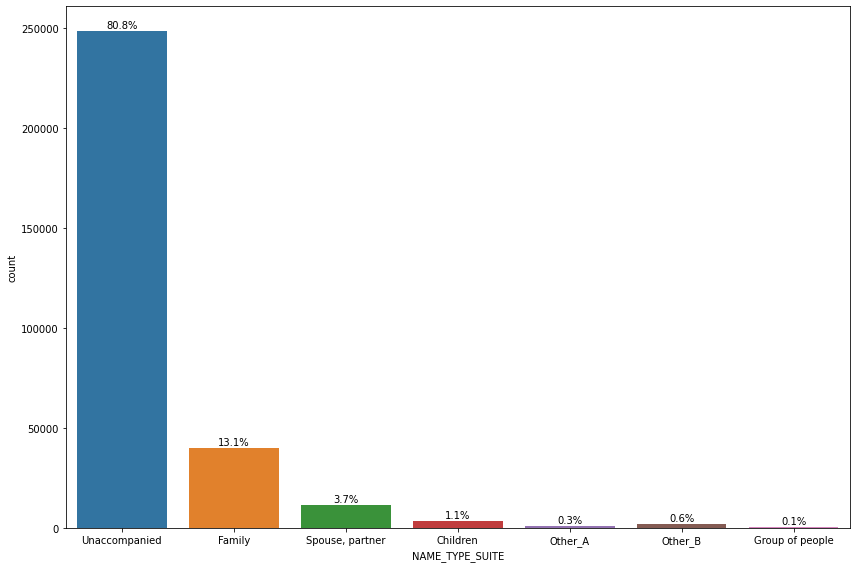

...

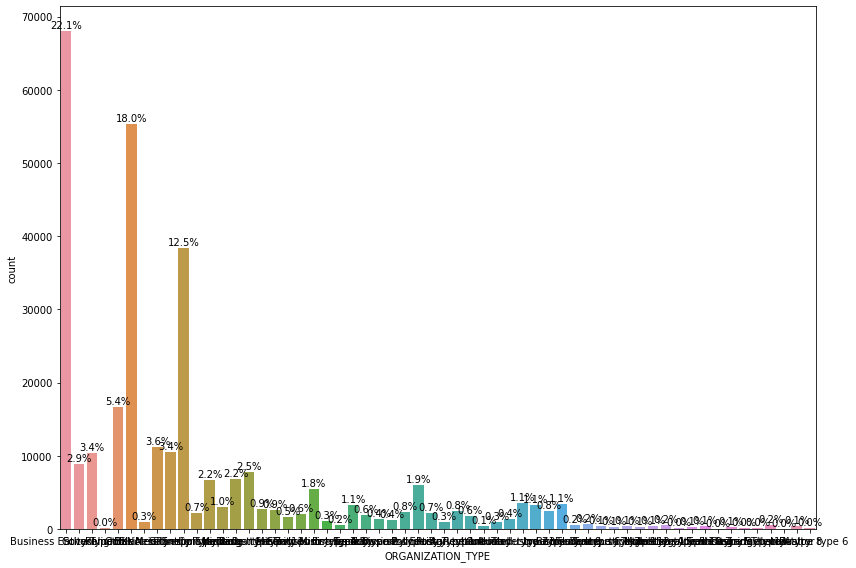

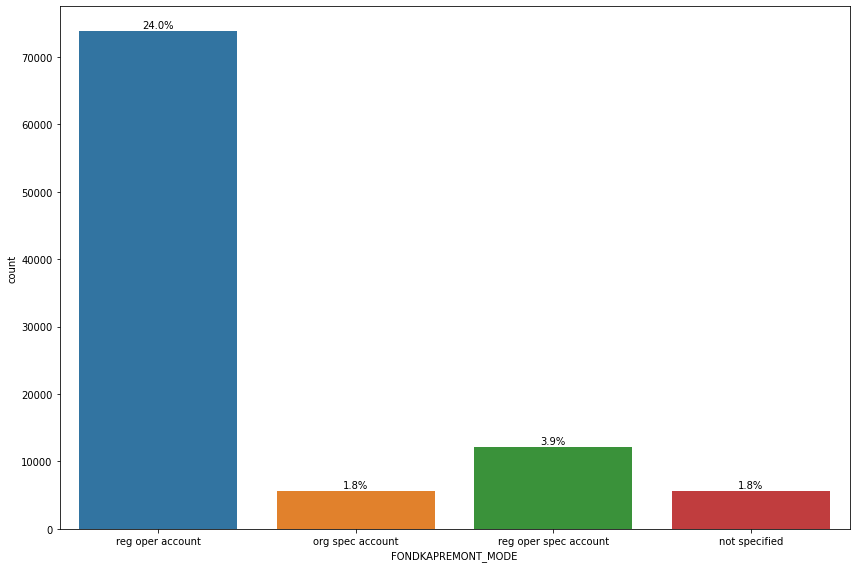

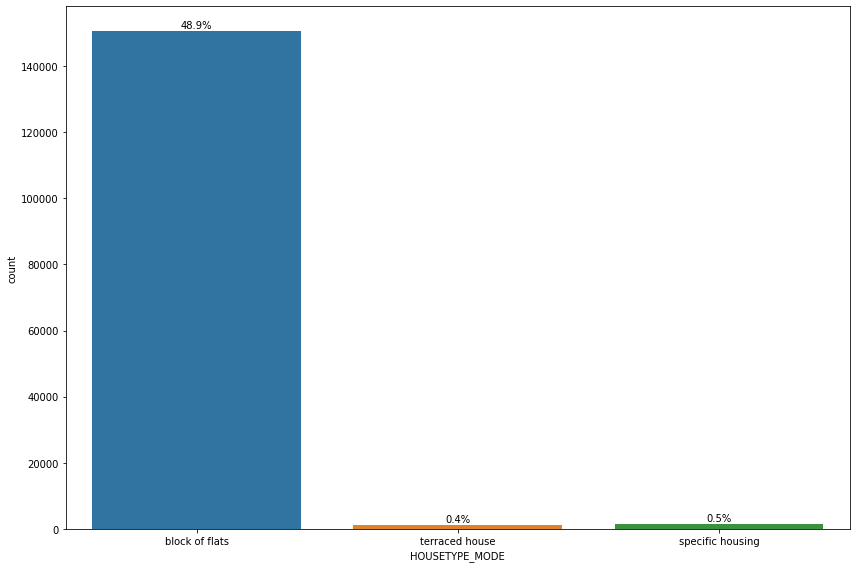

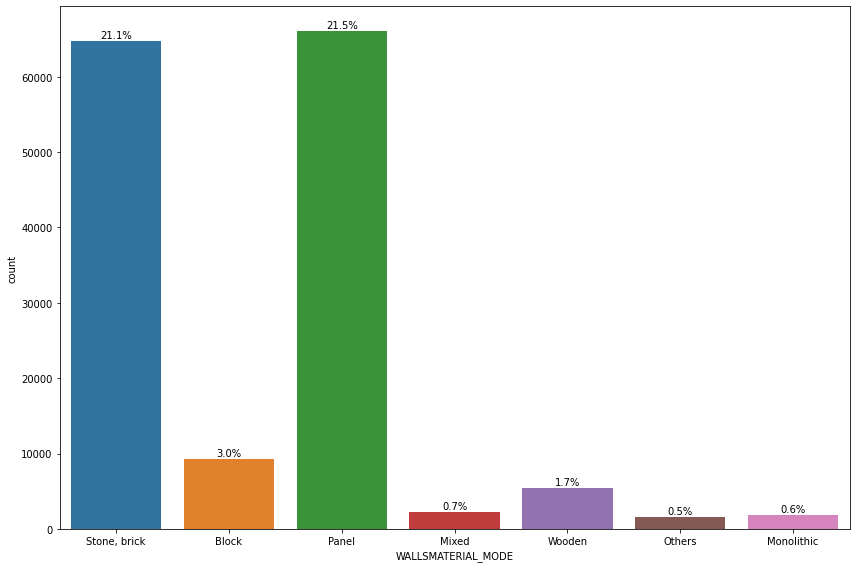

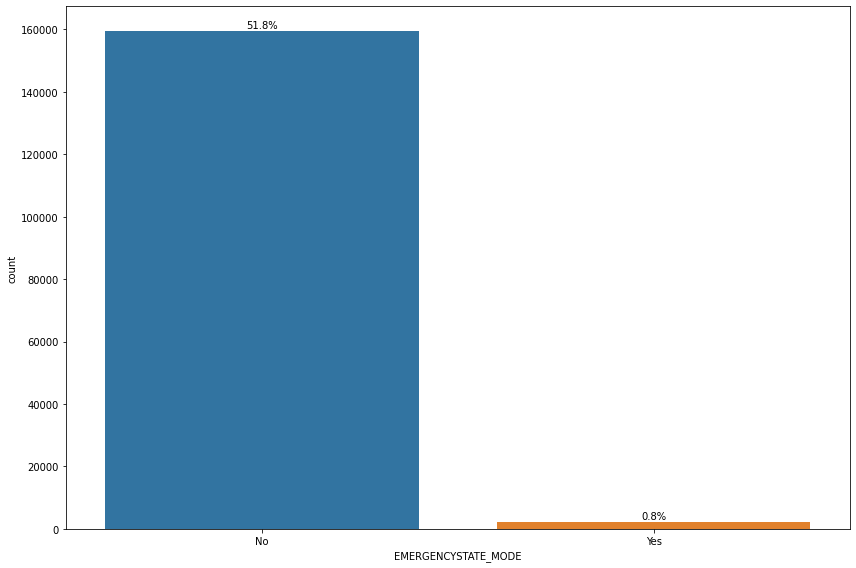

In [24]:
# Barchart visusalisation for categorical variable,
# if nbr of unique value > 60 data viz using histogram
for column in cat_col:
    if df[column].nunique() < 60:
        barchart_percent(data=df,
        x=column)
    else:
        if df[column].dtype == 'object':
            print(column, df[column].nunique())
        else:    
            fig = plt.figure(figsize=(20, 5))


            plt.subplot(1, 2, 1)
            sns.histplot(x=data[column],
                        data=df,
                        kde=True)

            plt.subplot(1, 2, 2)
            sns.boxplot(x=data[column],
                        data=df)
            fig.tight_layout(pad=0.8)

            plt.show()

### Relationship Target/Features

In [25]:
# Creation of sub-group with TARGET = 0 and TARGET = 1

unpay_df = df[df['TARGET'] == 1]
pay_df = df[df['TARGET'] == 0]

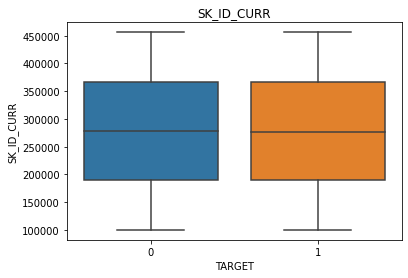

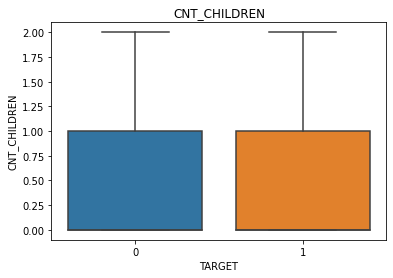

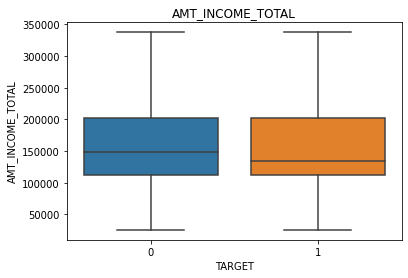

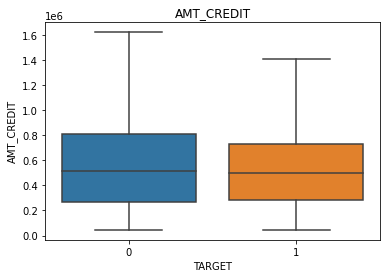

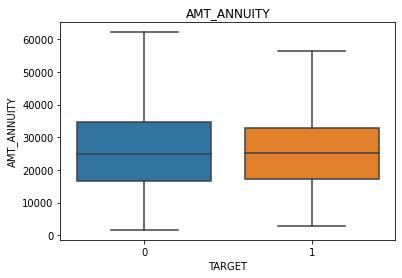

...

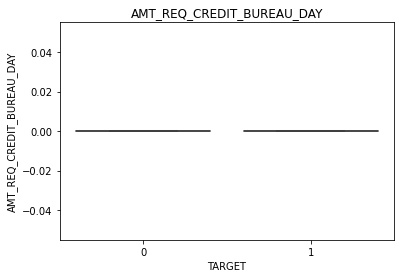

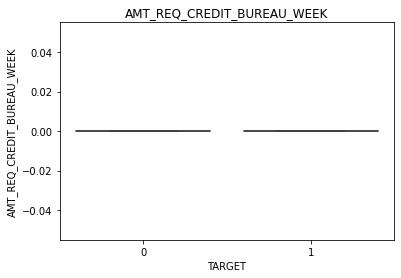

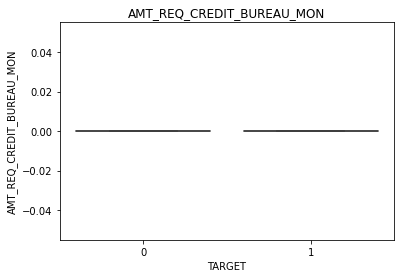

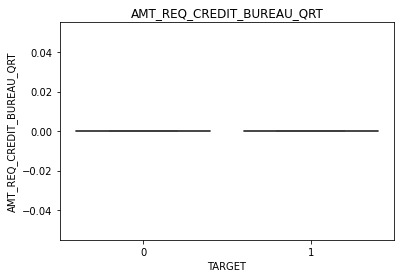

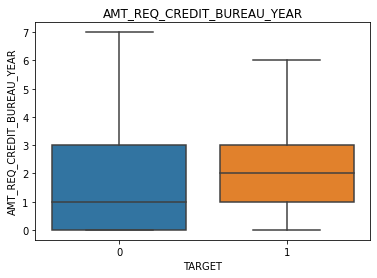

In [26]:
# Boxplot comparison for target values
for col in num_col:
    sns.boxplot(data=df,
                x='TARGET',
                y=col,
                showfliers=False)
    plt.title(col)
    plt.show()

In [27]:
# Evaluation using ANOVA if their is a relationship between a features and the target
#ANOVA for TARGET
import scipy.stats as stats

dv = 'TARGET'
ivs = num_col
print('TARGET')
result = []

for iv in ivs:
# Create dataset for each TARGET
    target_value = df.groupby(dv)[iv]
    datasets = {}
    for groups, data in target_value:
        datasets[groups] = data
    
    fvalue, pvalue = stats.f_oneway(datasets[0].dropna(),
                                    datasets[1].dropna())
    result.append([iv,
                   fvalue,
                   pvalue])
    
    print(f' {iv :_<50} {fvalue :_<20} {pvalue}')

TARGET
 SK_ID_CURR________________________________________ 1.3670808805411832__ 0.24231496893115526
 CNT_CHILDREN______________________________________ 113.2499302441547___ 1.9224915500910093e-26
 AMT_INCOME_TOTAL__________________________________ 4.875710505224813___ 0.02723796087829524
 AMT_CREDIT________________________________________ 283.8753868374507___ 1.1474602724260586e-63
 AMT_ANNUITY_______________________________________ 50.51906227468382___ 1.1826767819645638e-12
 AMT_GOODS_PRICE___________________________________ 483.6499838475441___ 4.153757129739688e-107
 REGION_POPULATION_RELATIVE________________________ 426.7560281004843___ 9.582701564553064e-95
 DAYS_BIRTH________________________________________ 1893.9760872580603__ 0.0
 DAYS_EMPLOYED_____________________________________ 622.0717419812712___ 3.6311730827265075e-137
 DAYS_REGISTRATION_________________________________ 542.7530288906132___ 6.0365534541554926e-120
 DAYS_ID_PUBLISH___________________________________ 816.3

In [29]:
# Select the 20 lowest pvalue
display(pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20])
interest_col = pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20]['features']

,features,fvalue,pvalue
30,EXT_SOURCE_3,8153.346064,0.000000e+00
29,EXT_SOURCE_2,8110.573549,0.000000e+00
28,EXT_SOURCE_1,3315.682630,0.000000e+00
7,DAYS_BIRTH,1893.976087,0.000000e+00
20,REGION_RATING_CLIENT_W_CITY,1144.461405,2.078455e-250
19,REGION_RATING_CLIENT,1070.491250,2.172433e-234
78,DAYS_LAST_PHONE_CHANGE,940.484389,3.188161e-206
10,DAYS_ID_PUBLISH,816.396507,2.527524e-179
26,REG_CITY_NOT_WORK_CITY,801.742167,3.805463e-176
13,FLAG_EMP_PHONE,651.563766,1.442660e-143


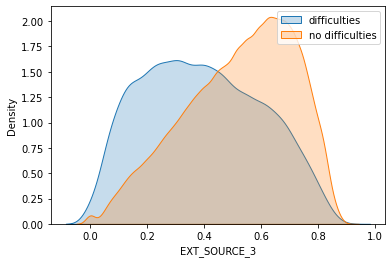

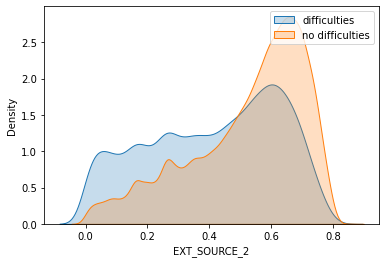

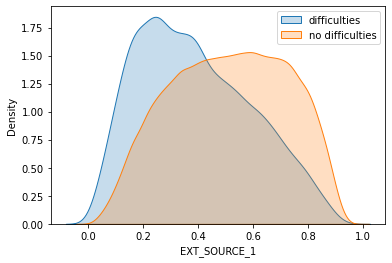

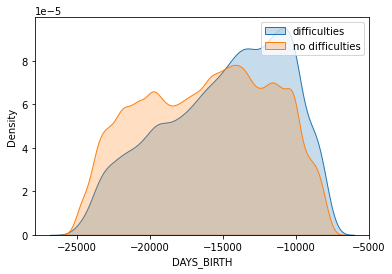

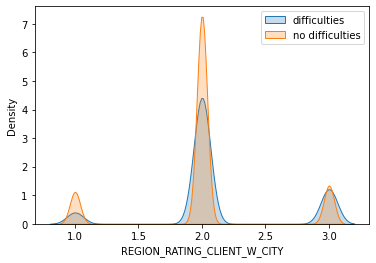

...

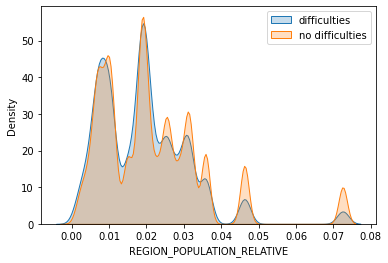

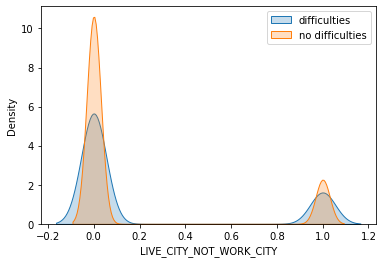

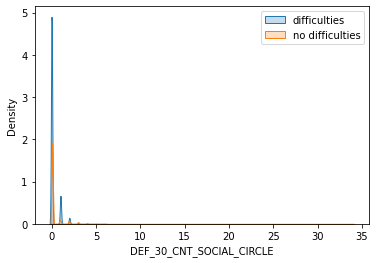

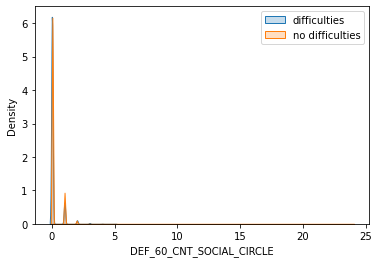

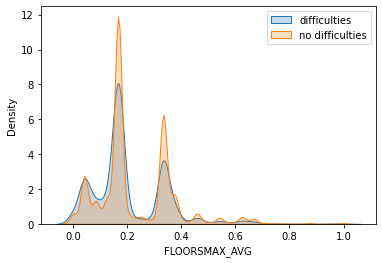

In [30]:
# Show density plot for best 10 pvalue
for col in interest_col:
    plt.figure()
    sns.kdeplot(unpay_df[col], label='difficulties', shade=True)
    sns.kdeplot(pay_df[col], label='no difficulties', shade=True)
    plt.legend()

### Relationship Target / Categorical variables

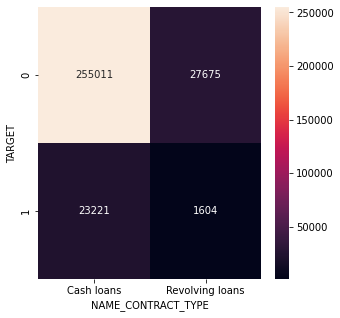

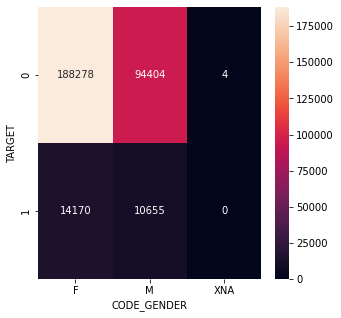

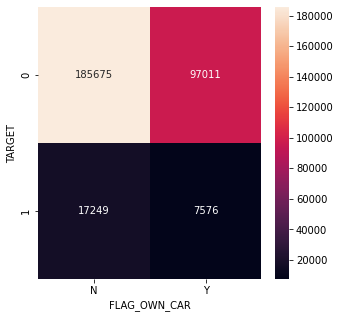

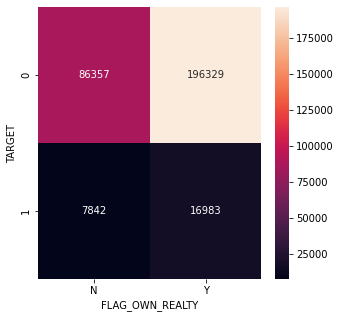

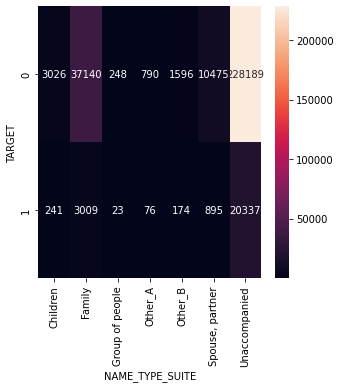

...

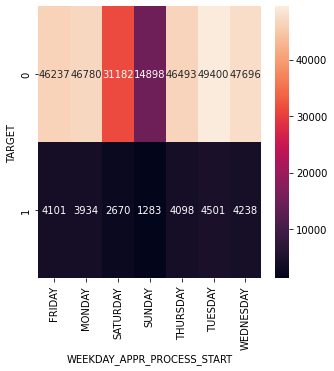

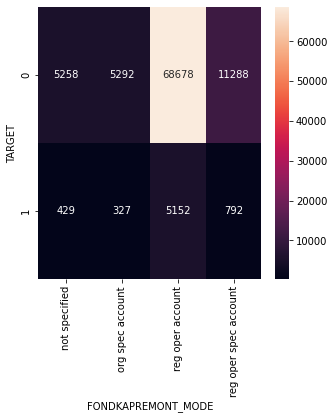

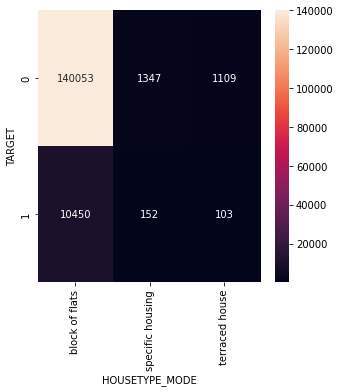

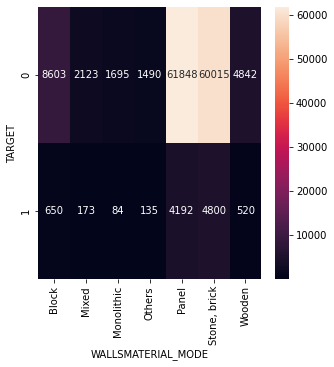

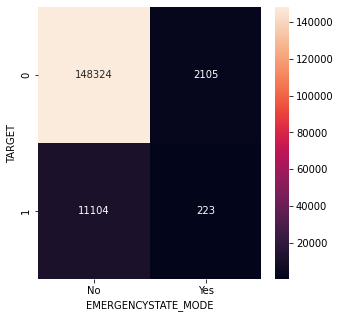

In [31]:
# Crosstable for all categorical variable vs TARGET
for col in cat_col:
    if df[col].nunique() < 20: 
        plt.figure(figsize=(5, 5))
        sns.heatmap(pd.crosstab(df['TARGET'], df[col]), annot=True, fmt='d') 

In [32]:
def cramers_corrected_stat(x, y):
    """ 
    calculate Cramers V statistic for categorial-categorial association.
    uses correction from Bergsma and Wicher, 
    Journal of the Korean Statistical Society 42 (2013): 323-328
    """
    result = -1
    if len(x.value_counts()) == 1:
        print("First variable is constant")
    elif len(y.value_counts()) == 1:
        print("Second variable is constant")
    else:
        conf_matrix = pd.crosstab(x, y)

        if conf_matrix.shape[0] == 2:
            correct = False
        else:
            correct = True

        chi2 = stats.chi2_contingency(conf_matrix, correction=correct)[0]

        n = sum(conf_matrix.sum())
        phi2 = chi2/n
        r, k = conf_matrix.shape
        phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
        rcorr = r - ((r-1)**2)/(n-1)
        kcorr = k - ((k-1)**2)/(n-1)
        result = np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))
    return round(result, 2)

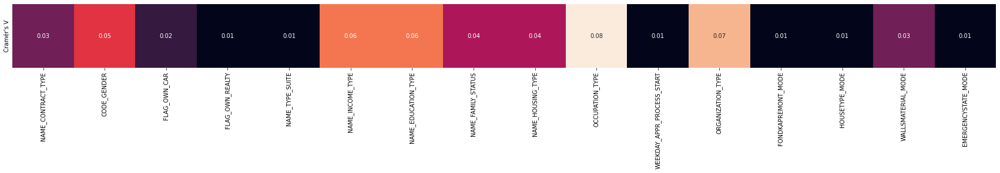

In [33]:
# The Cramer's V score is between 0 and 1 and allow use to evaluate the dependency between two variable
cramers_tab = pd.DataFrame(np.ones((1, len(cat_col)), dtype=float))

cramers_tab.columns = cat_col
cramers_tab.index = ["TARGET"]

for col in cat_col:
    phi = cramers_corrected_stat(df["TARGET"], df[col])
    cramers_tab.loc["TARGET", col] = phi
    
plt.figure(figsize=(30, 2))
sns.heatmap(cramers_tab, annot=True, cbar=False)
plt.ylabel('Cramér\'s V')
plt.yticks([])
plt.show()


### Features/Features Relationship
#### numeric/numeric

In [34]:
# First, I wille keep features which are triple _AVG, _MEDI, _MODE
import re
flag_list = []
unflag_list = []
for col in df[num_col].columns:
    if re.search('_MODE|_AVG|_MEDI', col):
        flag_list.append(col)
    else:
        unflag_list.append(col)
flag_list.sort()

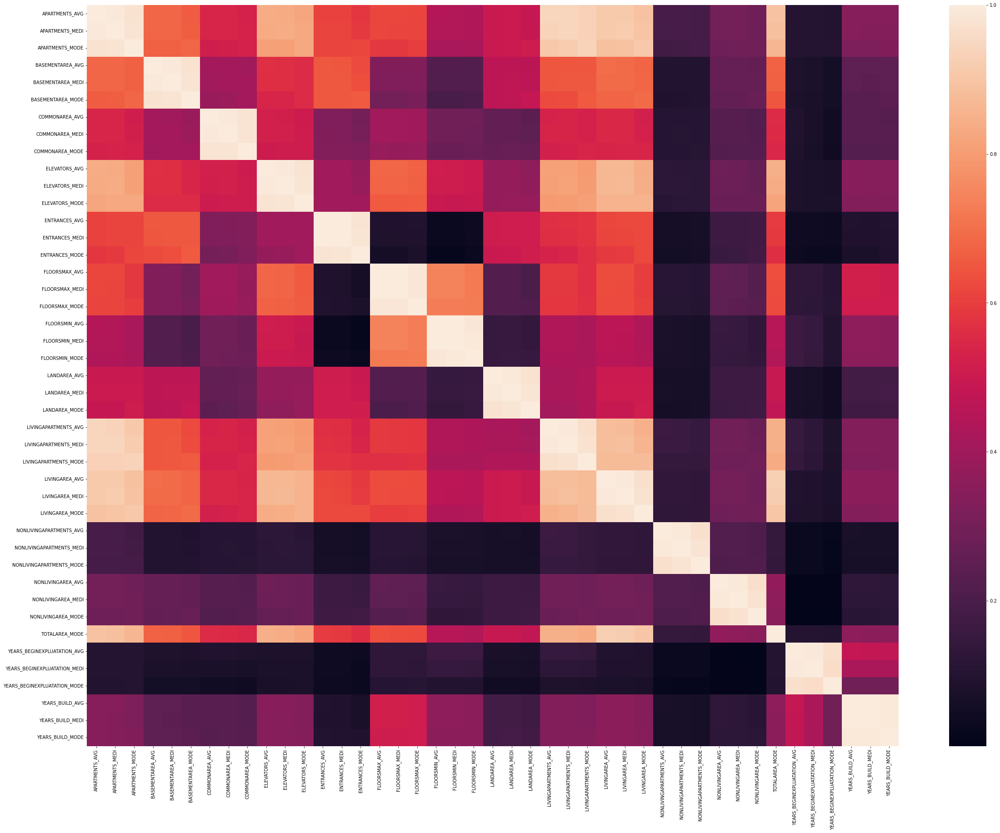

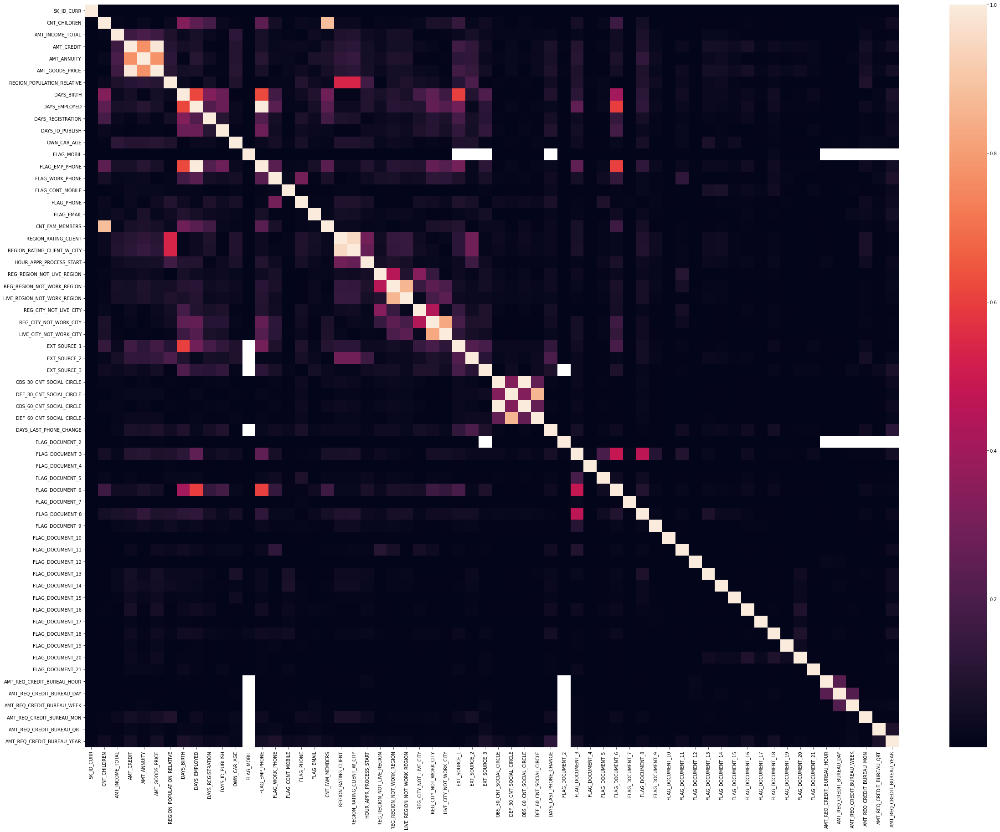

In [35]:
# Analyse of features/features relation
plt.figure(figsize=(40,30))
sns.heatmap(np.abs(df[flag_list].corr()))
plt.show()

plt.figure(figsize=(40,30))
sns.heatmap(np.abs(df[unflag_list].corr()))
plt.show()

Some variable a link because they are repeated this is the case of _AVG, _MOD, _MEDI ending variable, we are probably going to keep only one of each to avoid collinearity

In [36]:
# Check correlation > to .5 or < to -.5 for 
corr = df.corr()
double_check = []
result = []
for row in corr.index:
    for col in corr.columns:
        double_check.append(col + row)
        if (row + col not in double_check):
            if (row != col) and (corr.loc[row, col] > 0.5) or (corr.loc[row, col] < -0.5):
                result.append([row,
                                col,
                                corr.loc[row, col],
                                np.abs(corr.loc[row, col])])
                print(f'{row :-<5} {col:-<50} {corr.loc[row, col]} ')

CNT_CHILDREN CNT_FAM_MEMBERS----------------------------------- 0.879160640438957 
AMT_CREDIT AMT_ANNUITY--------------------------------------- 0.7701380033118846 
AMT_CREDIT AMT_GOODS_PRICE----------------------------------- 0.9869683054221499 
AMT_ANNUITY AMT_GOODS_PRICE----------------------------------- 0.7751092733120319 
REGION_POPULATION_RELATIVE REGION_RATING_CLIENT------------------------------ -0.5328765312383351 
REGION_POPULATION_RELATIVE REGION_RATING_CLIENT_W_CITY----------------------- -0.5315354521931355 
DAYS_BIRTH DAYS_EMPLOYED------------------------------------- -0.6158641964711599 
DAYS_BIRTH FLAG_EMP_PHONE------------------------------------ 0.6198876962023361 
DAYS_BIRTH EXT_SOURCE_1-------------------------------------- -0.6006099739503155 
DAYS_EMPLOYED FLAG_EMP_PHONE------------------------------------ -0.999755011444388 
DAYS_EMPLOYED FLAG_DOCUMENT_6----------------------------------- 0.597484437373503 
FLAG_EMP_PHONE FLAG_DOCUMENT_6-------------------------

### Categorical/Categorical

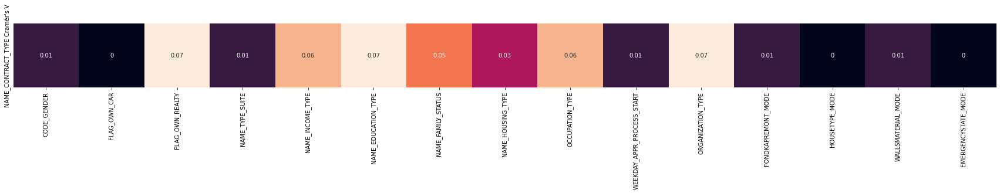

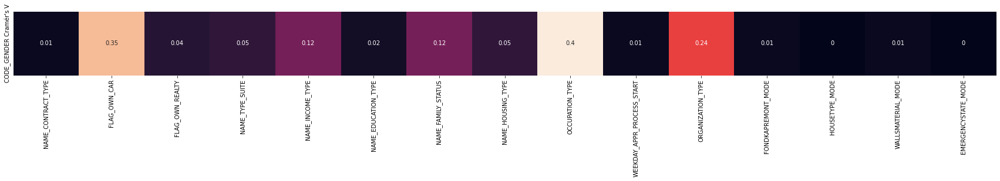

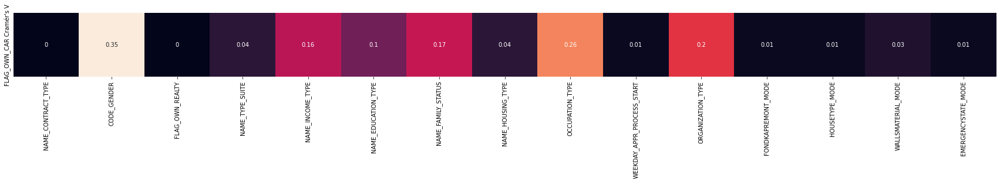

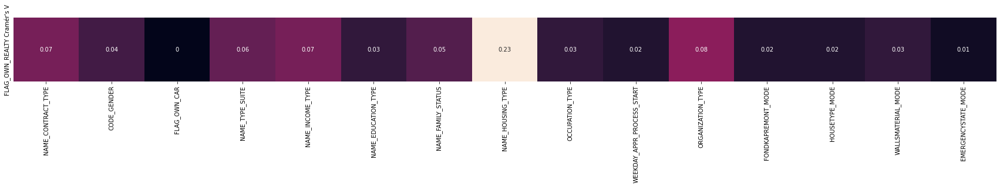

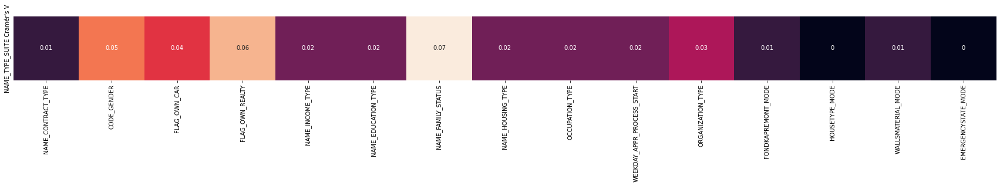

...

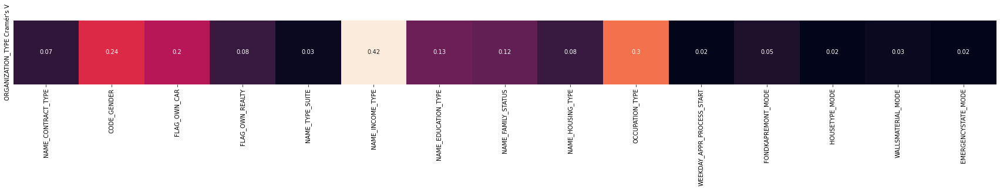

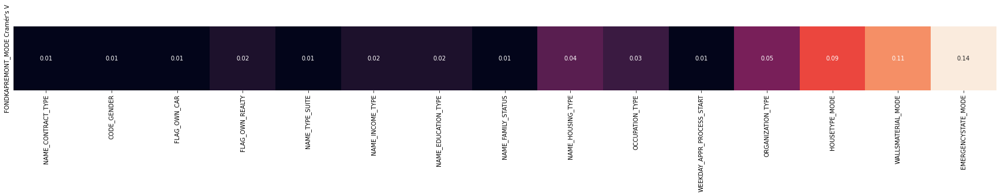

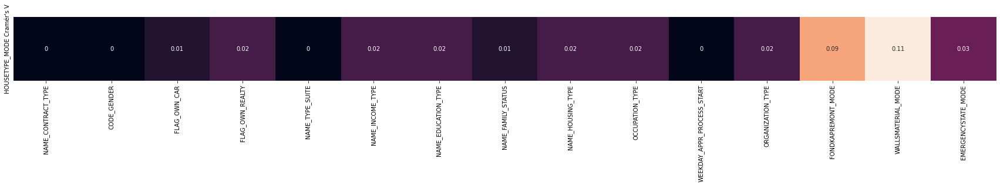

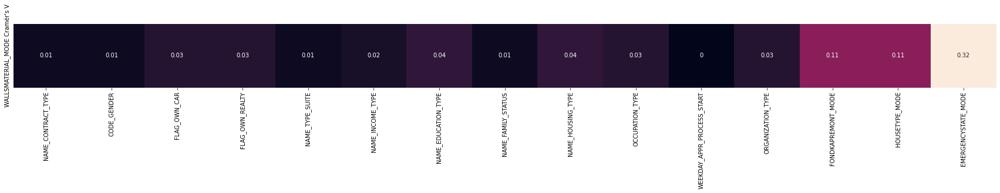

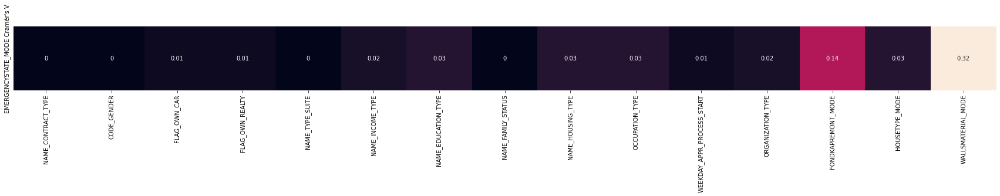

In [34]:
# Evaluation of relatioship between each categorical variable using Cramer's V
for col in cat_col:
    tmp_col = [elem for elem in cat_col if elem != col]
    cramers_tab = pd.DataFrame(np.ones((1, len(tmp_col)), dtype=float))

    cramers_tab.columns = tmp_col
    cramers_tab.index = [col]

    for col2 in cat_col:
        if col != col2:
            phi = cramers_corrected_stat(df[col], df[col2])
            cramers_tab.loc[col, col2] = phi
        
    plt.figure(figsize=(30, 2))
    sns.heatmap(cramers_tab, annot=True, cbar=False)
    plt.ylabel(f'{col} Cramér\'s V')
    plt.yticks([])
    plt.show()

### Feature engineering

In [37]:
# Create array with features to remove for modelisation
# Features engineering for application train (Kernel Kaggle)

# NaN values for DAYS_EMPLOYED: 365.243 -> nan
df['DAYS_EMPLOYED'].replace(365243, np.nan, inplace= True)
# Some simple new features (percentages)
df['DAYS_EMPLOYED_PERC'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']
df['INCOME_CREDIT_PERC'] = df['AMT_INCOME_TOTAL'] / df['AMT_CREDIT']
df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']
df['ANNUITY_INCOME_PERC'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
df['PAYMENT_RATE'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']

# Categorical features with Binary encode (0 or 1; two categories)
for bin_feature in ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']:
    df[bin_feature], uniques = pd.factorize(df[bin_feature])

# Remove _MODE and _MEDI and FLAG_DOCUMENT features (EDA)
rm = []
idx_filling = filling_factor(df)[filling_factor(df)['filling_factor'] < 60]
num_col = df.select_dtypes(include=np.number).columns.to_list()
for col in df.columns:
    if re.search('_MODE|_MEDI|FLAG_DOCUMENT_', col) and col != 'TOTALAREA_MODE':
        rm.append(col)
    elif col in idx_filling['column_name'].to_list():
        rm.append(col)
        
for col in rm:
    if col in interest_col.tolist(): 
        rm.remove(col)

In [38]:
df.drop(rm, axis=1, inplace=True)

In [39]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,FLOORSMAX_AVG,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_3,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_PERC,INCOME_CREDIT_PERC,INCOME_PER_PERSON,ANNUITY_INCOME_PERC,PAYMENT_RATE
0,100002,1,Cash loans,0,0,0,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637.0,-3648.0,-2120,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0833,2.0,2.0,2.0,2.0,-1134.0,1,0.0,0.0,0.0,0.0,0.0,1.0,0.067329,0.498036,202500.0,0.121978,0.060749
1,100003,0,Cash loans,1,0,1,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188.0,-1186.0,-291,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.2917,1.0,0.0,1.0,0.0,-828.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.070862,0.208736,135000.0,0.132217,0.027598
2,100004,0,Revolving loans,0,1,0,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225.0,-4260.0,-2531,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,0.0,0.0,0.0,0.0,-815.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.011814,0.500000,67500.0,0.100000,0.050000
3,100006,0,Cash loans,1,0,0,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039.0,-9833.0,-2437,1,1,0,1,0,0,Laborers,2.0,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,NaN,0.650442,NaN,NaN,2.0,0.0,2.0,0.0,-617.0,1,NaN,NaN,NaN,NaN,NaN,NaN,0.159905,0.431748,67500.0,0.219900,0.094941
4,100007,0,Cash loans,0,0,0,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038.0,-4311.0,-3458,1,1,0,1,0,0,Core staff,1.0,2,2,THURSDAY,11,0,0,0,0,1,1,Religion,NaN,0.322738,NaN,NaN,0.0,0.0,0.0,0.0,-1106.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.152418,0.236842,121500.0,0.179963,0.042623


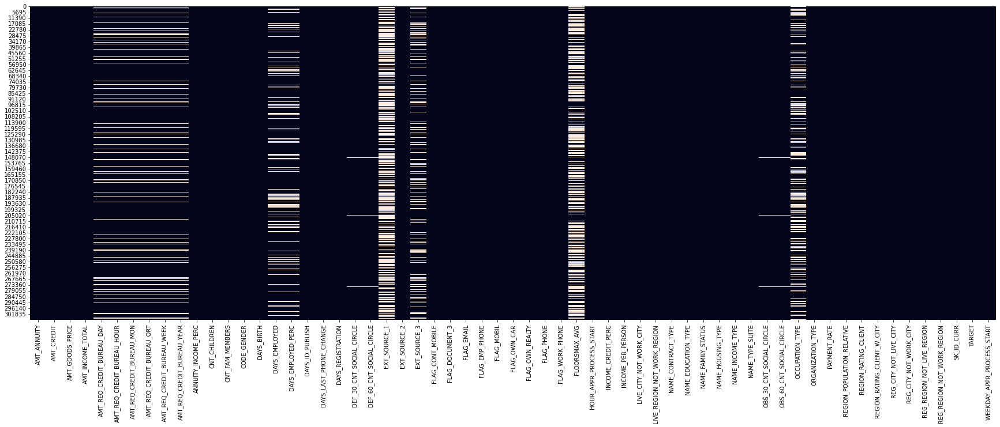

In [40]:
plt.figure(figsize=(30,10))
sns.heatmap(df[sorted(df.columns)].isna(), cbar=False)
plt.show()

## Bureau and bureau_balance

In [42]:
# One-hot encoding for categorical columns with get_dummies
def one_hot_encoder(df, nan_as_category = True):
    original_columns = list(df.columns)
    categorical_columns = [col for col in df.columns if df[col].dtype == 'object']
    df = pd.get_dummies(df, columns= categorical_columns, dummy_na= nan_as_category)
    new_columns = [c for c in df.columns if c not in original_columns]
    return df, new_columns

In [46]:
# Aggregation and merging to df 
bureau = pd.read_csv('data/bureau.csv')
bb = pd.read_csv('data/bureau_balance.csv')
bb, bb_cat = one_hot_encoder(bb, False)
bureau, bureau_cat = one_hot_encoder(bureau, False)

# Bureau balance: Perform aggregations and merge with bureau.csv
bb_aggregations = {'MONTHS_BALANCE': ['min', 'max', 'size']}
for col in bb_cat:
    bb_aggregations[col] = ['mean']
bb_agg = bb.groupby('SK_ID_BUREAU').agg(bb_aggregations)
bb_agg.columns = pd.Index([e[0] + "_" + e[1].upper() for e in bb_agg.columns.tolist()])
bureau = bureau.join(bb_agg, how='left', on='SK_ID_BUREAU')
bureau.drop(['SK_ID_BUREAU'], axis=1, inplace= True)
del bb, bb_agg
gc.collect()

# Bureau and bureau_balance numeric features
num_aggregations = {
    'DAYS_CREDIT': ['min', 'max', 'mean', 'var'],
    'DAYS_CREDIT_ENDDATE': ['min', 'max', 'mean'],
    'DAYS_CREDIT_UPDATE': ['mean'],
    'CREDIT_DAY_OVERDUE': ['max', 'mean'],
    'AMT_CREDIT_MAX_OVERDUE': ['mean'],
    'AMT_CREDIT_SUM': ['max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_DEBT': ['max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_OVERDUE': ['mean'],
    'AMT_CREDIT_SUM_LIMIT': ['mean', 'sum'],
    'AMT_ANNUITY': ['max', 'mean'],
    'CNT_CREDIT_PROLONG': ['sum'],
    'MONTHS_BALANCE_MIN': ['min'],
    'MONTHS_BALANCE_MAX': ['max'],
    'MONTHS_BALANCE_SIZE': ['mean', 'sum']
}
# Bureau and bureau_balance categorical features
cat_aggregations = {}
for cat in bureau_cat: cat_aggregations[cat] = ['mean']
for cat in bb_cat: cat_aggregations[cat + "_MEAN"] = ['mean']

bureau_agg = bureau.groupby('SK_ID_CURR').agg({**num_aggregations, **cat_aggregations})
bureau_agg.columns = pd.Index(['BURO_' + e[0] + "_" + e[1].upper() for e in bureau_agg.columns.tolist()])
# Bureau: Active credits - using only numerical aggregations
active = bureau[bureau['CREDIT_ACTIVE_Active'] == 1]
active_agg = active.groupby('SK_ID_CURR').agg(num_aggregations)
active_agg.columns = pd.Index(['ACTIVE_' + e[0] + "_" + e[1].upper() for e in active_agg.columns.tolist()])
bureau_agg = bureau_agg.join(active_agg, how='left', on='SK_ID_CURR')
del active, active_agg
gc.collect()
# Bureau: Closed credits - using only numerical aggregations
closed = bureau[bureau['CREDIT_ACTIVE_Closed'] == 1]
closed_agg = closed.groupby('SK_ID_CURR').agg(num_aggregations)
closed_agg.columns = pd.Index(['CLOSED_' + e[0] + "_" + e[1].upper() for e in closed_agg.columns.tolist()])
bureau_agg = bureau_agg.join(closed_agg, how='left', on='SK_ID_CURR')
del closed, closed_agg, bureau
gc.collect()

0

### Shape Analysis

float64    108
int64        4
dtype: int64


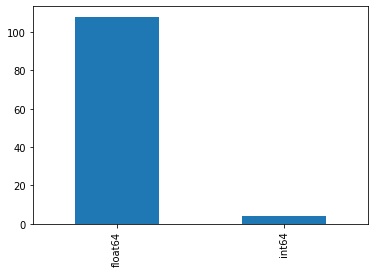

In [47]:
# Count features type
print(bureau_agg.dtypes.value_counts())

#Show feautres type count
bureau_agg.dtypes.value_counts().plot.bar()
plt.show()

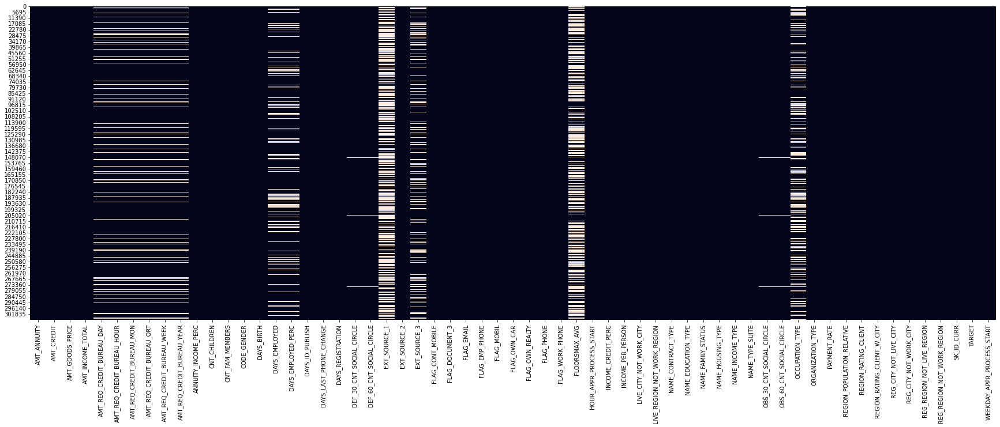

,column_name,missing_count,filling_factor
0,ACTIVE_AMT_ANNUITY_MAX,213085,30.321342
1,ACTIVE_AMT_ANNUITY_MEAN,213085,30.321342
2,CLOSED_AMT_ANNUITY_MEAN,210614,31.129358
3,CLOSED_AMT_ANNUITY_MAX,210614,31.129358
4,ACTIVE_MONTHS_BALANCE_SIZE_MEAN,194662,36.345651
5,ACTIVE_MONTHS_BALANCE_MAX_MAX,194662,36.345651
6,ACTIVE_MONTHS_BALANCE_MIN_MIN,194662,36.345651
7,BURO_AMT_ANNUITY_MEAN,187587,38.659172
8,BURO_AMT_ANNUITY_MAX,187587,38.659172
9,CLOSED_MONTHS_BALANCE_MAX_MAX,187316,38.747789


In [48]:
# SHow missing values
plt.figure(figsize=(30,10))
sns.heatmap(df[sorted(df.columns)].isna(), cbar=False)
plt.show()

display(filling_factor(bureau_agg))

### Univariate analysis

In [ ]:
 # Visualisation of continous variable 
EDA_continous(bureau_agg)

### Features/features relationship

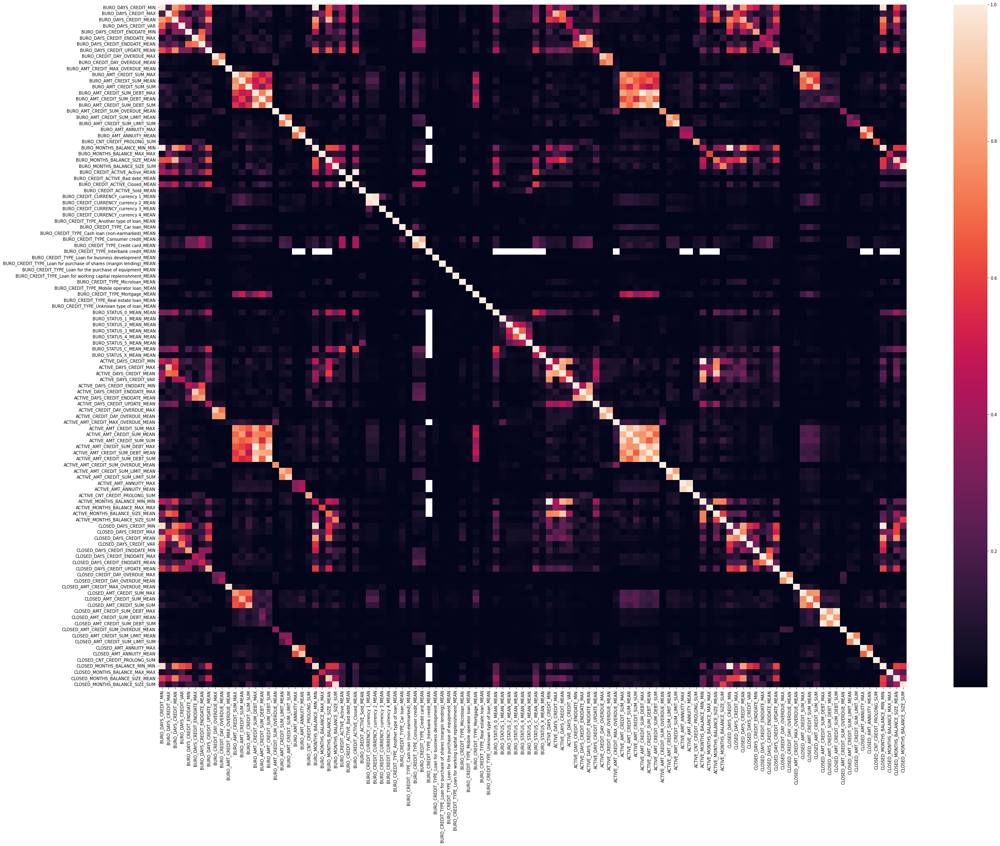

In [49]:
# Analyse of features/features relation
plt.figure(figsize=(40,30))
sns.heatmap(np.abs(bureau_agg.corr()))
plt.show()

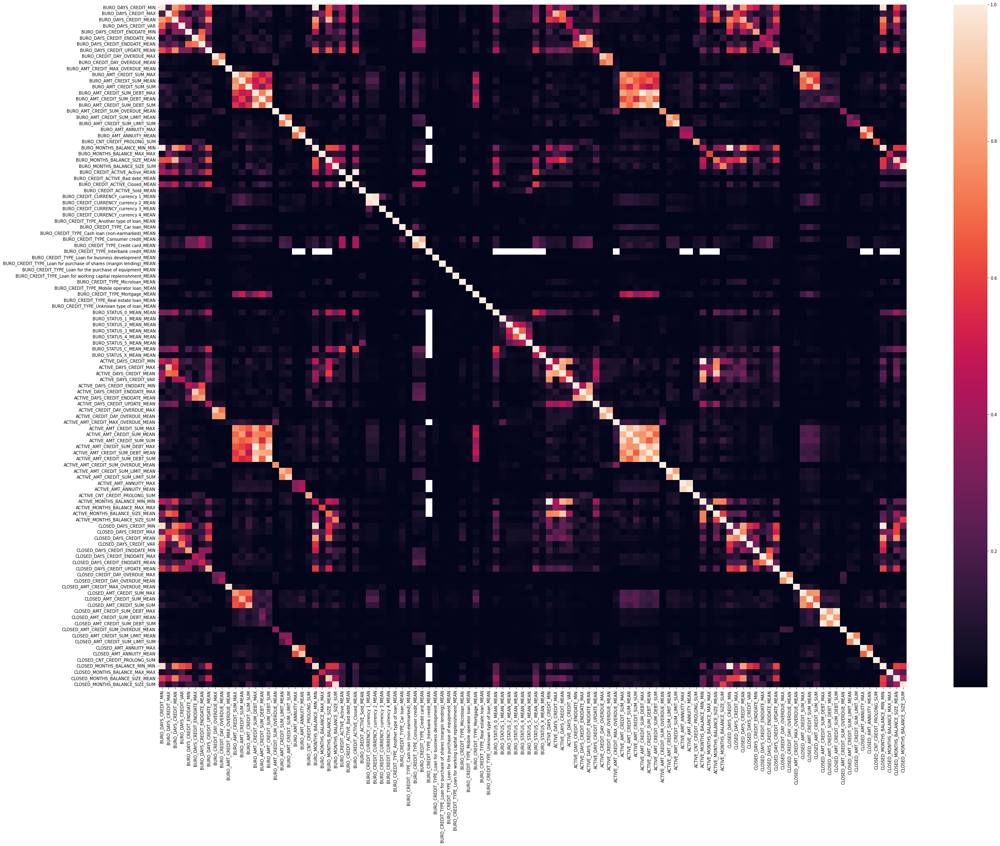

BURO_DAYS_CREDIT_MIN BURO_MONTHS_BALANCE_MIN_MIN----------------------- 0.9998552330207338 
BURO_DAYS_CREDIT_MIN CLOSED_DAYS_CREDIT_MIN---------------------------- 0.9660958861245897 
BURO_DAYS_CREDIT_MIN CLOSED_MONTHS_BALANCE_MIN_MIN--------------------- 0.965645417480418 
BURO_DAYS_CREDIT_ENDDATE_MAX ACTIVE_DAYS_CREDIT_ENDDATE_MAX-------------------- 0.9115418505240698 
BURO_CREDIT_DAY_OVERDUE_MAX ACTIVE_CREDIT_DAY_OVERDUE_MAX--------------------- 0.9181846434474947 
BURO_AMT_CREDIT_MAX_OVERDUE_MEAN CLOSED_AMT_CREDIT_MAX_OVERDUE_MEAN---------------- 0.9576951845227212 
BURO_AMT_CREDIT_SUM_DEBT_MAX BURO_AMT_CREDIT_SUM_DEBT_SUM---------------------- 0.955127465780629 
BURO_AMT_CREDIT_SUM_DEBT_MAX ACTIVE_AMT_CREDIT_SUM_DEBT_MAX-------------------- 0.9969192833115315 
BURO_AMT_CREDIT_SUM_DEBT_MAX ACTIVE_AMT_CREDIT_SUM_DEBT_SUM-------------------- 0.950720956089336 
BURO_AMT_CREDIT_SUM_DEBT_SUM ACTIVE_AMT_CREDIT_SUM_DEBT_MAX-------------------- 0.9500596046930739 
BURO_AMT_CREDIT_SUM_DEBT

In [50]:
### Features/features relationship
# Analyse of features/features relation
plt.figure(figsize=(40,30))
sns.heatmap(np.abs(bureau_agg.corr()))
plt.show()
# Check correlation > to .5 or < to -.5 for 
corr = bureau_agg.corr()
double_check = []
corr_col = []
for row in corr.index:
    for col in corr.columns:
        double_check.append(col + row)
        if (row + col not in double_check):
            if (row != col) and (corr.loc[row, col] > 0.9) or (corr.loc[row, col] < -0.9):
                corr_col.append(col)
                print(f'{row :-<5} {col:-<50} {corr.loc[row, col]} ')

### Target/features relationship

In [51]:
df = df.join(bureau_agg, how='left', on='SK_ID_CURR')
bureau_col = bureau_agg.columns

In [52]:
# Evaluation using ANOVA if their is a relationship between a features and the target
#ANOVA for TARGET
import scipy.stats as stats

dv = 'TARGET'
ivs = bureau_col
print('TARGET')
result = []

for iv in ivs:
# Create dataset for each TARGET
    target_value = df.groupby(dv)[iv]
    datasets = {}
    for groups, data in target_value:
        datasets[groups] = data
    
    fvalue, pvalue = stats.f_oneway(datasets[0].dropna(),
                                    datasets[1].dropna())
    result.append([iv,
                   fvalue,
                   pvalue])
    
    print(f' {iv :_<50} {fvalue :_<20} {pvalue}')

TARGET
 BURO_DAYS_CREDIT_MIN______________________________ 1500.4495703283533__ 0.0
 BURO_DAYS_CREDIT_MAX______________________________ 654.6146960890818___ 3.329157094760015e-144
 BURO_DAYS_CREDIT_MEAN_____________________________ 2138.6445497208233__ 0.0
 BURO_DAYS_CREDIT_VAR______________________________ 336.53855341812744__ 4.102630962968703e-75
 BURO_DAYS_CREDIT_ENDDATE_MIN______________________ 307.36902890736906__ 8.950780235400094e-69
 BURO_DAYS_CREDIT_ENDDATE_MAX______________________ 350.2173406246009___ 4.2759336474191787e-78
 BURO_DAYS_CREDIT_ENDDATE_MEAN_____________________ 577.9314573656503___ 1.45586992755236e-127
 BURO_DAYS_CREDIT_UPDATE_MEAN______________________ 1257.8067697441952__ 7.47133665621662e-275
 BURO_CREDIT_DAY_OVERDUE_MAX_______________________ 7.949425168336024___ 0.004810624113432481
 BURO_CREDIT_DAY_OVERDUE_MEAN______________________ 17.36751774805197___ 3.08143906229562e-05
 BURO_AMT_CREDIT_MAX_OVERDUE_MEAN__________________ 1.0901698838294334__ 0.2964

In [53]:
# Select the 20 lowest pvalue
display(pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20])
interest_col = pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20]['features']

,features,fvalue,pvalue
0,BURO_DAYS_CREDIT_MIN,1500.449570,0.000000e+00
2,BURO_DAYS_CREDIT_MEAN,2138.644550,0.000000e+00
29,BURO_CREDIT_ACTIVE_Closed_MEAN,1670.349626,0.000000e+00
27,BURO_CREDIT_ACTIVE_Active_MEAN,1586.187826,0.000000e+00
7,BURO_DAYS_CREDIT_UPDATE_MEAN,1257.806770,7.471337e-275
60,ACTIVE_DAYS_CREDIT_MEAN,894.205554,4.477817e-196
85,CLOSED_DAYS_CREDIT_MIN,865.043565,8.790653e-190
59,ACTIVE_DAYS_CREDIT_MAX,795.365550,1.137635e-174
87,CLOSED_DAYS_CREDIT_MEAN,790.053472,1.545778e-173
1,BURO_DAYS_CREDIT_MAX,654.614696,3.329157e-144


In [54]:
# Creation of sub-group with TARGET = 0 and TARGET = 1
gc.collect()
unpay_df = df[df['TARGET'] == 1]
pay_df = df[df['TARGET'] == 0]

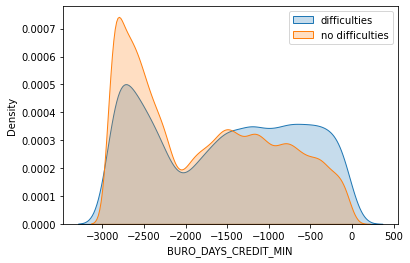

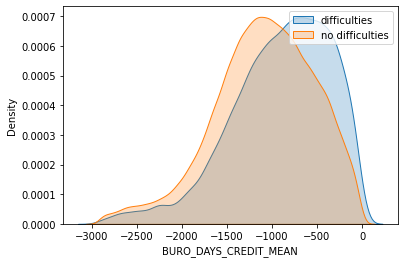

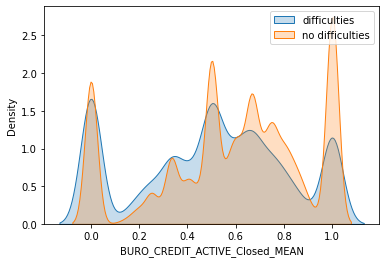

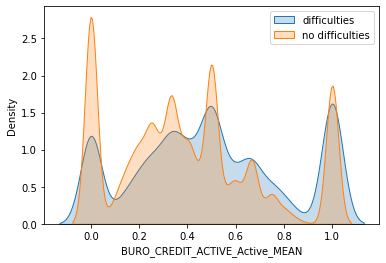

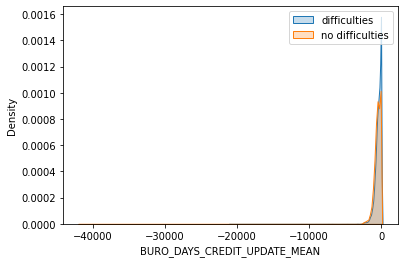

...

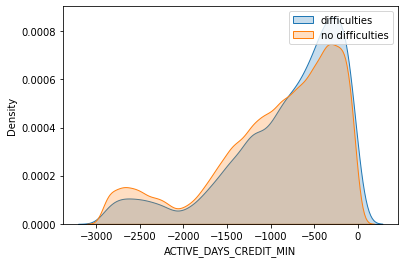

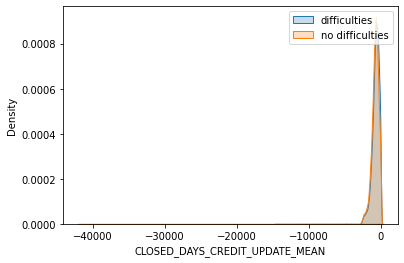

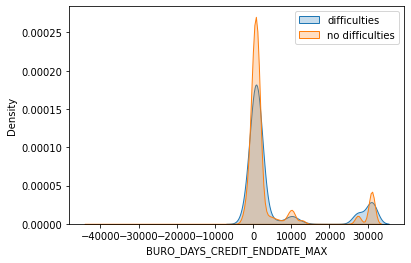

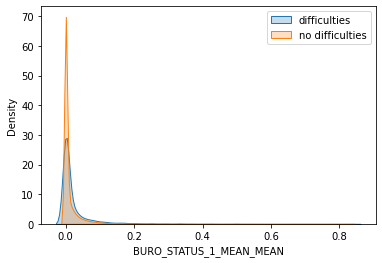

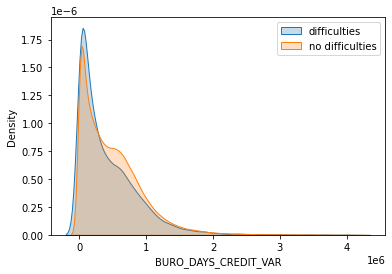

In [55]:
# Show density plot for best 10 pvalue
for col in interest_col:
    plt.figure()
    sns.kdeplot(unpay_df[col], label='difficulties', shade=True)
    sns.kdeplot(pay_df[col], label='no difficulties', shade=True)
    plt.legend()

### Feature engineering

In [56]:
# Remove features (EDA)
rm = []

idx_filling = filling_factor(bureau_agg)[filling_factor(bureau_agg)['filling_factor'] < 60]
idx_filling

# remove col with less than 60% filling unless it is correlated to TARGET
for col in bureau_agg:
    if col in idx_filling['column_name'].to_list():
        rm.append(col)

for col in rm:
    if col in interest_col.tolist(): 
        rm.remove(col)

# remove correlated features
for col in corr_col:
    rm.append(col)

df.drop(rm, axis=1, inplace=True)

## Previous application

In [58]:
# Aggregation of prev 

prev = pd.read_csv('data/previous_application.csv')
prev, cat_cols = one_hot_encoder(prev, nan_as_category=True)
# Days 365.243 values -> nan
prev['DAYS_FIRST_DRAWING'].replace(365243, np.nan, inplace= True)
prev['DAYS_FIRST_DUE'].replace(365243, np.nan, inplace= True)
prev['DAYS_LAST_DUE_1ST_VERSION'].replace(365243, np.nan, inplace= True)
prev['DAYS_LAST_DUE'].replace(365243, np.nan, inplace= True)
prev['DAYS_TERMINATION'].replace(365243, np.nan, inplace= True)
# Add feature: value ask / value received percentage
prev['APP_CREDIT_PERC'] = prev['AMT_APPLICATION'] / prev['AMT_CREDIT']
# Previous applications numeric features
num_aggregations = {
    'AMT_ANNUITY': ['min', 'max', 'mean'],
    'AMT_APPLICATION': ['min', 'max', 'mean'],
    'AMT_CREDIT': ['min', 'max', 'mean'],
    'APP_CREDIT_PERC': ['min', 'max', 'mean', 'var'],
    'AMT_DOWN_PAYMENT': ['min', 'max', 'mean'],
    'AMT_GOODS_PRICE': ['min', 'max', 'mean'],
    'HOUR_APPR_PROCESS_START': ['min', 'max', 'mean'],
    'RATE_DOWN_PAYMENT': ['min', 'max', 'mean'],
    'DAYS_DECISION': ['min', 'max', 'mean'],
    'CNT_PAYMENT': ['mean', 'sum'],
}
# Previous applications categorical features
cat_aggregations = {}
for cat in cat_cols:
    cat_aggregations[cat] = ['mean']

prev_agg = prev.groupby('SK_ID_CURR').agg({**num_aggregations, **cat_aggregations})
prev_agg.columns = pd.Index(['PREV_' + e[0] + "_" + e[1].upper() for e in prev_agg.columns.tolist()])
# Previous Applications: Approved Applications - only numerical features
approved = prev[prev['NAME_CONTRACT_STATUS_Approved'] == 1]
approved_agg = approved.groupby('SK_ID_CURR').agg(num_aggregations)
approved_agg.columns = pd.Index(['APPROVED_' + e[0] + "_" + e[1].upper() for e in approved_agg.columns.tolist()])
prev_agg = prev_agg.join(approved_agg, how='left', on='SK_ID_CURR')
# Previous Applications: Refused Applications - only numerical features
refused = prev[prev['NAME_CONTRACT_STATUS_Refused'] == 1]
refused_agg = refused.groupby('SK_ID_CURR').agg(num_aggregations)
refused_agg.columns = pd.Index(['REFUSED_' + e[0] + "_" + e[1].upper() for e in refused_agg.columns.tolist()])
prev_agg = prev_agg.join(refused_agg, how='left', on='SK_ID_CURR')
del refused, refused_agg, approved, approved_agg, prev
gc.collect()

69559

### Shape and feature analysis

In [67]:
def exploratory_data(df):

    print('Shape analysis')
    # Count features type
    print(df.shape)
    print(df.dtypes.value_counts())

    #Show feaures type count
    df.dtypes.value_counts().plot.bar()
    plt.show()

    print('Missing values')
    plt.figure(figsize=(30,10))
    sns.heatmap(df[sorted(df.columns)].isna(), cbar=False)
    plt.show()

    display(filling_factor(df))

    print('-------------------------------------------------')
    print('Univariate Analysis')
    #EDA_continous(df)


    print('-------------------------------------------------')
    print('Features/features relationship')
    # Analyse of features/features relation
    plt.figure(figsize=(40,30))
    sns.heatmap(np.abs(df.corr()))
    plt.show()

    # Check correlation > to .5 or < to -.5 for 
    corr = df.corr()
    double_check = []
    corr_col = []
    for row in corr.index:
        for col in corr.columns:
            double_check.append(col + row)
            if (row + col not in double_check):
                if (row != col) and (corr.loc[row, col] > 0.9) or (corr.loc[row, col] < -0.9):
                    corr_col.append(col)
                    print(f'{row :-<5} {col:-<50} {corr.loc[row, col]} ')
    
    return corr_col

Shape analysis
(338857, 249)
float64    245
int64        4
dtype: int64


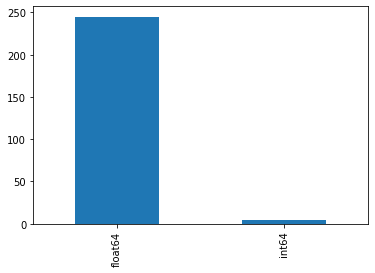

Missing values


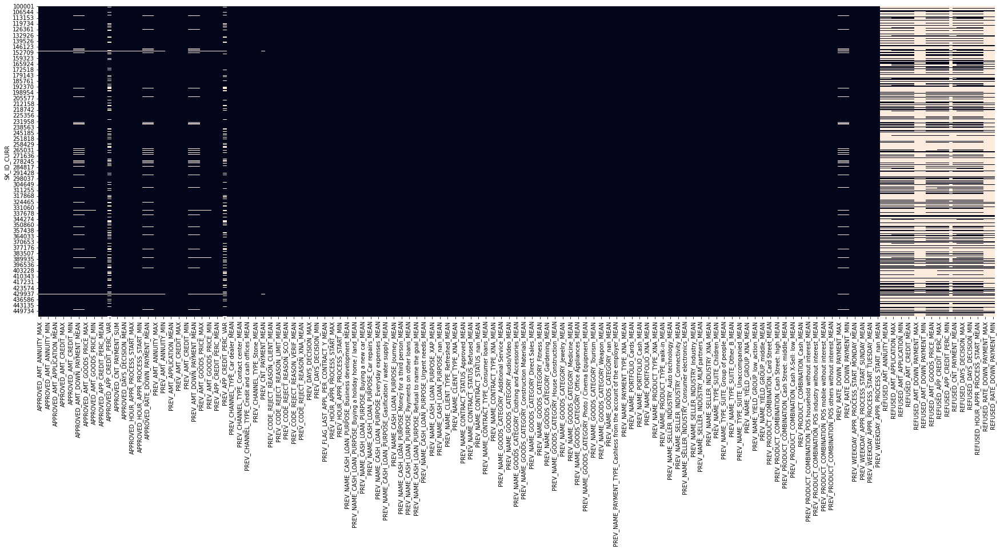

,column_name,missing_count,filling_factor
0,ACTIVE_AMT_ANNUITY_MAX,213085,30.321342
1,ACTIVE_AMT_ANNUITY_MEAN,213085,30.321342
2,CLOSED_AMT_ANNUITY_MEAN,210614,31.129358
3,CLOSED_AMT_ANNUITY_MAX,210614,31.129358
4,ACTIVE_MONTHS_BALANCE_SIZE_MEAN,194662,36.345651
5,ACTIVE_MONTHS_BALANCE_MAX_MAX,194662,36.345651
6,ACTIVE_MONTHS_BALANCE_MIN_MIN,194662,36.345651
7,BURO_AMT_ANNUITY_MEAN,187587,38.659172
8,BURO_AMT_ANNUITY_MAX,187587,38.659172
9,CLOSED_MONTHS_BALANCE_MAX_MAX,187316,38.747789


-------------------------------------------------
Univariate Analysis
-------------------------------------------------
Features/features relationship


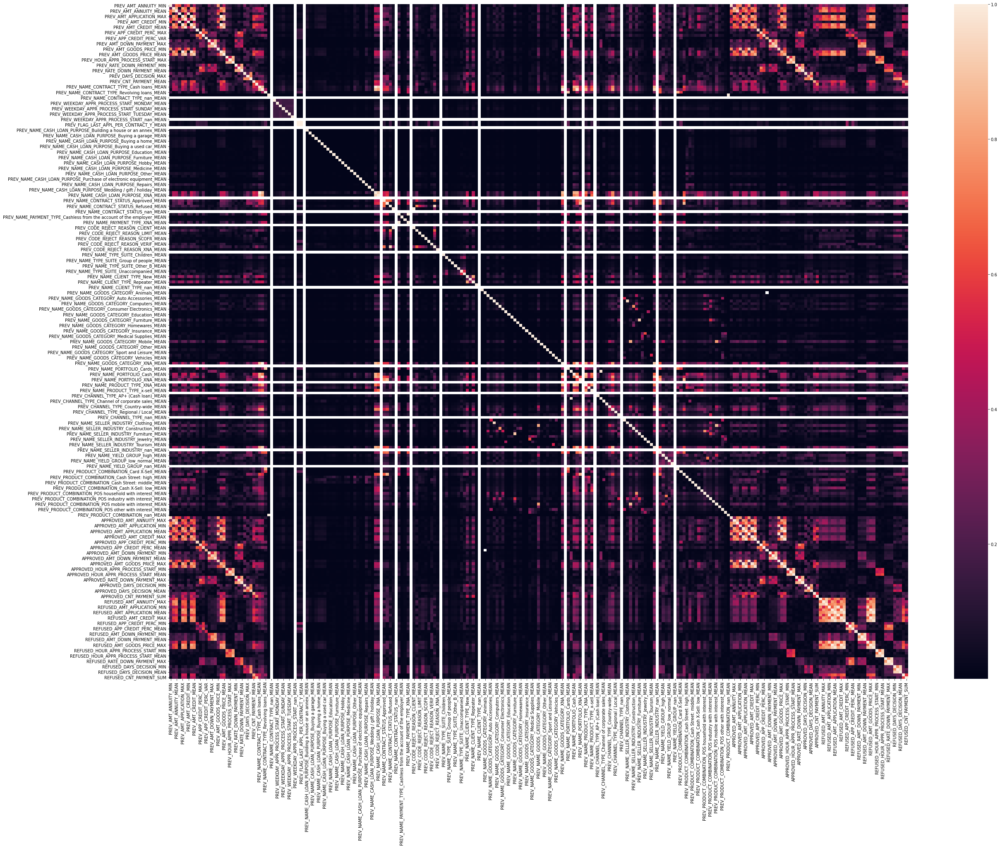

PREV_AMT_ANNUITY_MIN APPROVED_AMT_ANNUITY_MIN-------------------------- 0.9477095887970549 
PREV_AMT_ANNUITY_MAX APPROVED_AMT_ANNUITY_MAX-------------------------- 0.9125472139613368 
PREV_AMT_ANNUITY_MEAN APPROVED_AMT_ANNUITY_MEAN------------------------- 0.9366260421824264 
PREV_AMT_APPLICATION_MIN PREV_AMT_CREDIT_MIN------------------------------- 0.9609902819246284 
PREV_AMT_APPLICATION_MAX PREV_AMT_CREDIT_MAX------------------------------- 0.985600078385611 
PREV_AMT_APPLICATION_MAX PREV_AMT_GOODS_PRICE_MAX-------------------------- 0.999967314021483 
PREV_AMT_APPLICATION_MEAN PREV_AMT_CREDIT_MEAN------------------------------ 0.9760184190582523 
PREV_AMT_APPLICATION_MEAN PREV_AMT_GOODS_PRICE_MEAN------------------------- 0.9232569915054414 
PREV_AMT_CREDIT_MAX PREV_AMT_GOODS_PRICE_MAX-------------------------- 0.9857543119479838 
PREV_AMT_CREDIT_MEAN PREV_AMT_GOODS_PRICE_MEAN------------------------- 0.9188453821175979 
PREV_APP_CREDIT_PERC_MIN APPROVED_APP_CREDIT_PERC_MIN-------

In [60]:
corr_col = exploratory_data(prev_agg)

### Target feature analysis

In [61]:
df = df.join(prev_agg, how='left', on='SK_ID_CURR')
prev_col = prev_agg.columns

In [62]:
# Evaluation using ANOVA if their is a relationship between a features and the target
#ANOVA for TARGET
import scipy.stats as stats

dv = 'TARGET'
ivs = prev_col
print('TARGET')
result = []

for iv in ivs:
# Create dataset for each TARGET
    target_value = df.groupby(dv)[iv]
    datasets = {}
    for groups, data in target_value:
        datasets[groups] = data
    
    fvalue, pvalue = stats.f_oneway(datasets[0].dropna(),
                                    datasets[1].dropna())
    result.append([iv,
                   fvalue,
                   pvalue])
    
    #print(f' {iv :_<50} {fvalue :_<20} {pvalue}')

TARGET


/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3661: RuntimeWarning: invalid value encountered in subtract
  alldata -= offset
/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3669: RuntimeWarning: invalid value encountered in subtract
  ssbn += _square_of_sums(a - offset, axis=axis) / a.shape[axis]
/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())
/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())
/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3

In [63]:
# Select the 20 lowest pvalue
display(pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20])
interest_col = pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20]['features']

,features,fvalue,pvalue
74,PREV_NAME_CONTRACT_STATUS_Refused_MEAN,1766.549686,0.000000e+00
89,PREV_CODE_REJECT_REASON_XAP_MEAN,1599.549008,0.000000e+00
72,PREV_NAME_CONTRACT_STATUS_Approved_MEAN,1179.131268,6.899536e-258
141,PREV_NAME_PRODUCT_TYPE_walk-in_MEAN,962.526160,5.564688e-211
86,PREV_CODE_REJECT_REASON_SCOFR_MEAN,911.185987,7.411182e-200
83,PREV_CODE_REJECT_REASON_HC_MEAN,868.070999,1.637303e-190
25,PREV_DAYS_DECISION_MIN,833.387951,5.399027e-183
214,APPROVED_DAYS_DECISION_MIN,833.073411,6.329767e-183
27,PREV_DAYS_DECISION_MEAN,640.642082,3.448666e-141
191,APPROVED_AMT_ANNUITY_MEAN,575.497712,4.760631e-127


### Feature engineering

In [64]:
# Remove features (EDA)
rm = []

idx_filling = filling_factor(prev_agg)[filling_factor(prev_agg)['filling_factor'] < 60]
idx_filling

# remove col with less than 60% filling unless it is correlated to TARGET
for col in prev_agg:
    if col in idx_filling['column_name'].to_list():
        rm.append(col)

for col in rm:
    if col in interest_col.tolist(): 
        rm.remove(col)

# remove correlated features
for col in corr_col:
    rm.append(col)

df.drop(rm, axis=1, inplace=True)

## POS CASH balance

In [65]:
# Aggregation POS CASH Balance

pos = pd.read_csv('data/POS_CASH_balance.csv')
pos, cat_cols = one_hot_encoder(pos, nan_as_category= True)
# Features
aggregations = {
    'MONTHS_BALANCE': ['max', 'mean', 'size'],
    'SK_DPD': ['max', 'mean'],
    'SK_DPD_DEF': ['max', 'mean']
}
for cat in cat_cols:
    aggregations[cat] = ['mean']

pos_agg = pos.groupby('SK_ID_CURR').agg(aggregations)
pos_agg.columns = pd.Index(['POS_' + e[0] + "_" + e[1].upper() for e in pos_agg.columns.tolist()])
# Count pos cash accounts
pos_agg['POS_COUNT'] = pos.groupby('SK_ID_CURR').size()
del pos
gc.collect()

42095

### Shape and feature engineering

Shape analysis
(337252, 18)
float64    13
int64       5
dtype: int64


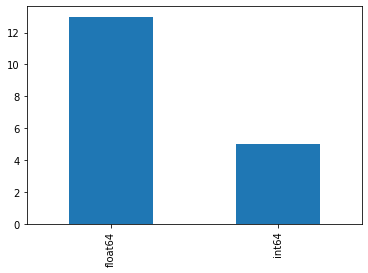

Missing values


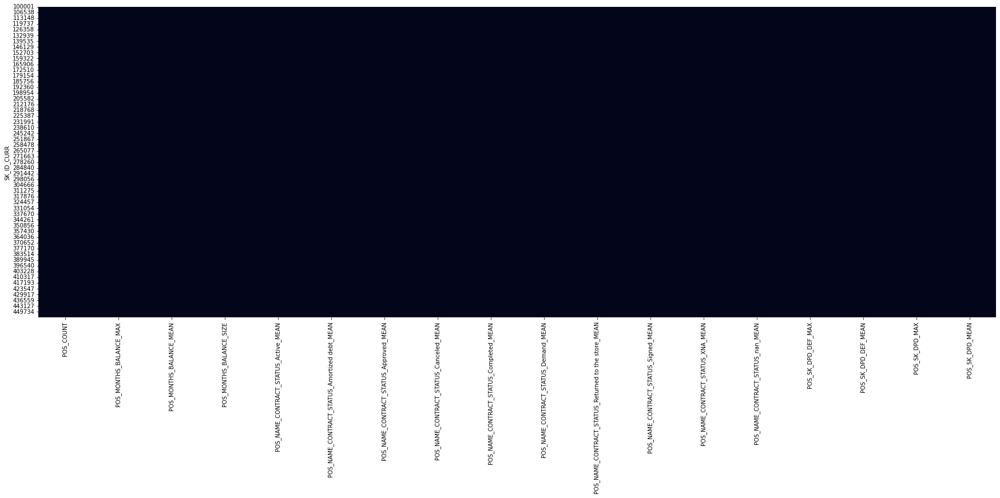

,column_name,missing_count,filling_factor
0,POS_MONTHS_BALANCE_MAX,0,100.0
1,POS_NAME_CONTRACT_STATUS_XNA_MEAN,0,100.0
2,POS_NAME_CONTRACT_STATUS_Signed_MEAN,0,100.0
3,POS_NAME_CONTRACT_STATUS_Returned to the store...,0,100.0
4,POS_NAME_CONTRACT_STATUS_Demand_MEAN,0,100.0
5,POS_NAME_CONTRACT_STATUS_Completed_MEAN,0,100.0
6,POS_NAME_CONTRACT_STATUS_Canceled_MEAN,0,100.0
7,POS_NAME_CONTRACT_STATUS_Approved_MEAN,0,100.0
8,POS_NAME_CONTRACT_STATUS_Amortized debt_MEAN,0,100.0
9,POS_NAME_CONTRACT_STATUS_Active_MEAN,0,100.0


-------------------------------------------------
Univariate Analysis
-------------------------------------------------
Features/features relationship


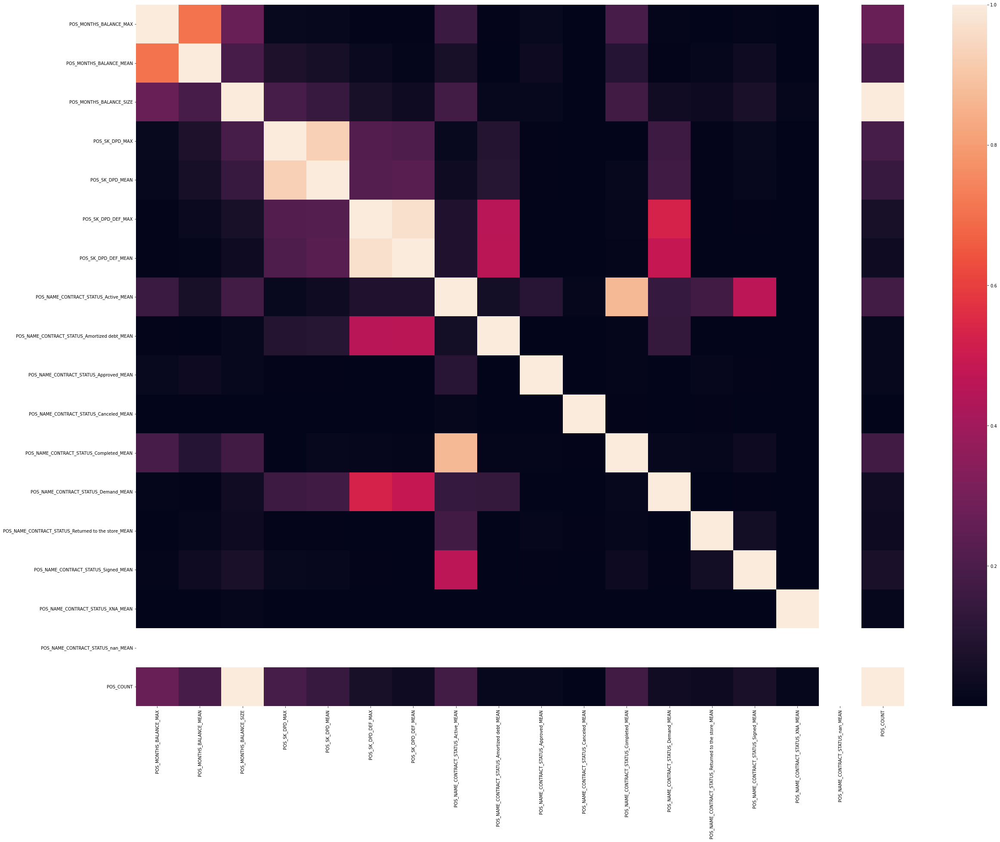

POS_MONTHS_BALANCE_SIZE POS_COUNT----------------------------------------- 1.0 
POS_SK_DPD_MAX POS_SK_DPD_MEAN----------------------------------- 0.9261275323947733 
POS_SK_DPD_DEF_MAX POS_SK_DPD_DEF_MEAN------------------------------- 0.9697326061589159 


In [68]:
corr_col = exploratory_data(pos_agg)

### Target feature analysis

In [69]:
df = df.join(pos_agg, how='left', on='SK_ID_CURR')
pos_col = pos_agg.columns

In [70]:
# Evaluation using ANOVA if their is a relationship between a features and the target
#ANOVA for TARGET
import scipy.stats as stats

dv = 'TARGET'
ivs = pos_col
print('TARGET')
result = []

for iv in ivs:
# Create dataset for each TARGET
    target_value = df.groupby(dv)[iv]
    datasets = {}
    for groups, data in target_value:
        datasets[groups] = data
    
    fvalue, pvalue = stats.f_oneway(datasets[0].dropna(),
                                    datasets[1].dropna())
    result.append([iv,
                   fvalue,
                   pvalue])
    
    print(f' {iv :_<50} {fvalue :_<20} {pvalue}')

TARGET
 POS_MONTHS_BALANCE_MAX____________________________ 5.404925716377281___ 0.02008069108509277
 POS_MONTHS_BALANCE_MEAN___________________________ 345.7745115396481___ 3.9118945080038596e-77
 POS_MONTHS_BALANCE_SIZE___________________________ 367.95360253543475__ 5.871926844995334e-82
 POS_SK_DPD_MAX____________________________________ 6.567105815520344___ 0.01038857561901445
 POS_SK_DPD_MEAN___________________________________ 8.552536068798926___ 0.0034506794795451934
 POS_SK_DPD_DEF_MAX________________________________ 26.567375409405077__ 2.5467212232106594e-07
 POS_SK_DPD_DEF_MEAN_______________________________ 12.21282753994024___ 0.00047469137967924444
 POS_NAME_CONTRACT_STATUS_Active_MEAN______________ 18.670840145815806__ 1.5539173279280503e-05
 POS_NAME_CONTRACT_STATUS_Amortized debt_MEAN______ 11.81366348005184___ 0.0005880588293094614
 POS_NAME_CONTRACT_STATUS_Approved_MEAN____________ 0.14123042375720637_ 0.7070611311496846
 POS_NAME_CONTRACT_STATUS_Canceled_MEAN_______

/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())


In [71]:
# Select the 20 lowest pvalue
display(pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20])
interest_col = pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20]['features']

,features,fvalue,pvalue
17,POS_COUNT,367.953603,5.871927e-82
2,POS_MONTHS_BALANCE_SIZE,367.953603,5.871927e-82
1,POS_MONTHS_BALANCE_MEAN,345.774512,3.911895e-77
13,POS_NAME_CONTRACT_STATUS_Returned to the store...,41.937597,9.438325e-11
14,POS_NAME_CONTRACT_STATUS_Signed_MEAN,31.867145,1.652398e-08
5,POS_SK_DPD_DEF_MAX,26.567375,2.546721e-07
7,POS_NAME_CONTRACT_STATUS_Active_MEAN,18.670840,1.553917e-05
12,POS_NAME_CONTRACT_STATUS_Demand_MEAN,15.009173,1.070134e-04
6,POS_SK_DPD_DEF_MEAN,12.212828,4.746914e-04
8,POS_NAME_CONTRACT_STATUS_Amortized debt_MEAN,11.813663,5.880588e-04


### Feature engineering

In [72]:
# Remove features (EDA)
rm = []

# remove correlated features
for col in corr_col:
    rm.append(col)

df.drop(rm, axis=1, inplace=True)

## Installment payment

In [73]:
ins = pd.read_csv('data/installments_payments.csv')
ins, cat_cols = one_hot_encoder(ins, nan_as_category= True)
# Percentage and difference paid in each installment (amount paid and installment value)
ins['PAYMENT_PERC'] = ins['AMT_PAYMENT'] / ins['AMT_INSTALMENT']
ins['PAYMENT_DIFF'] = ins['AMT_INSTALMENT'] - ins['AMT_PAYMENT']
# Days past due and days before due (no negative values)
ins['DPD'] = ins['DAYS_ENTRY_PAYMENT'] - ins['DAYS_INSTALMENT']
ins['DBD'] = ins['DAYS_INSTALMENT'] - ins['DAYS_ENTRY_PAYMENT']
ins['DPD'] = ins['DPD'].apply(lambda x: x if x > 0 else 0)
ins['DBD'] = ins['DBD'].apply(lambda x: x if x > 0 else 0)
# Features: Perform aggregations
aggregations = {
    'NUM_INSTALMENT_VERSION': ['nunique'],
    'DPD': ['max', 'mean', 'sum'],
    'DBD': ['max', 'mean', 'sum'],
    'PAYMENT_PERC': ['max', 'mean', 'sum', 'var'],
    'PAYMENT_DIFF': ['max', 'mean', 'sum', 'var'],
    'AMT_INSTALMENT': ['max', 'mean', 'sum'],
    'AMT_PAYMENT': ['min', 'max', 'mean', 'sum'],
    'DAYS_ENTRY_PAYMENT': ['max', 'mean', 'sum']
}
for cat in cat_cols:
    aggregations[cat] = ['mean']
ins_agg = ins.groupby('SK_ID_CURR').agg(aggregations)
ins_agg.columns = pd.Index(['INSTAL_' + e[0] + "_" + e[1].upper() for e in ins_agg.columns.tolist()])
# Count installments accounts
ins_agg['INSTAL_COUNT'] = ins.groupby('SK_ID_CURR').size()
del ins
gc.collect()

34805

### Shape and feature engineering   

Shape analysis
(339587, 26)
float64    24
int64       2
dtype: int64


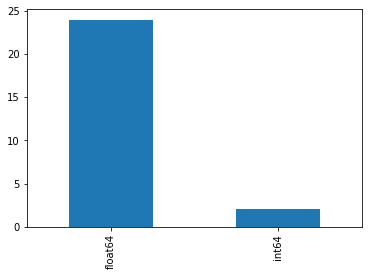

Missing values


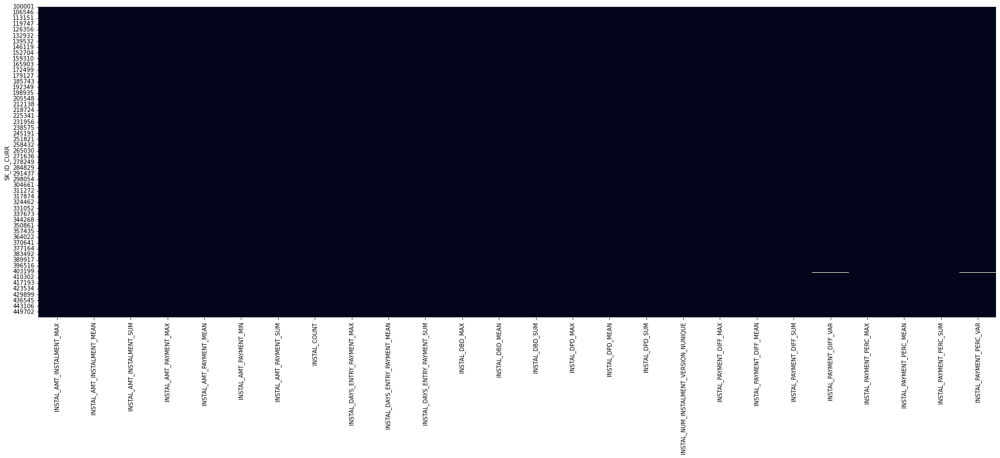

,column_name,missing_count,filling_factor
0,INSTAL_PAYMENT_PERC_VAR,996,99.706703
1,INSTAL_PAYMENT_DIFF_VAR,977,99.712298
2,INSTAL_PAYMENT_PERC_MEAN,28,99.991755
3,INSTAL_PAYMENT_PERC_SUM,19,99.994405
4,INSTAL_PAYMENT_DIFF_MEAN,9,99.997350
5,INSTAL_DAYS_ENTRY_PAYMENT_MEAN,9,99.997350
6,INSTAL_DAYS_ENTRY_PAYMENT_MAX,9,99.997350
7,INSTAL_AMT_PAYMENT_MEAN,9,99.997350
8,INSTAL_AMT_PAYMENT_MAX,9,99.997350
9,INSTAL_AMT_PAYMENT_MIN,9,99.997350


-------------------------------------------------
Univariate Analysis
-------------------------------------------------
Features/features relationship


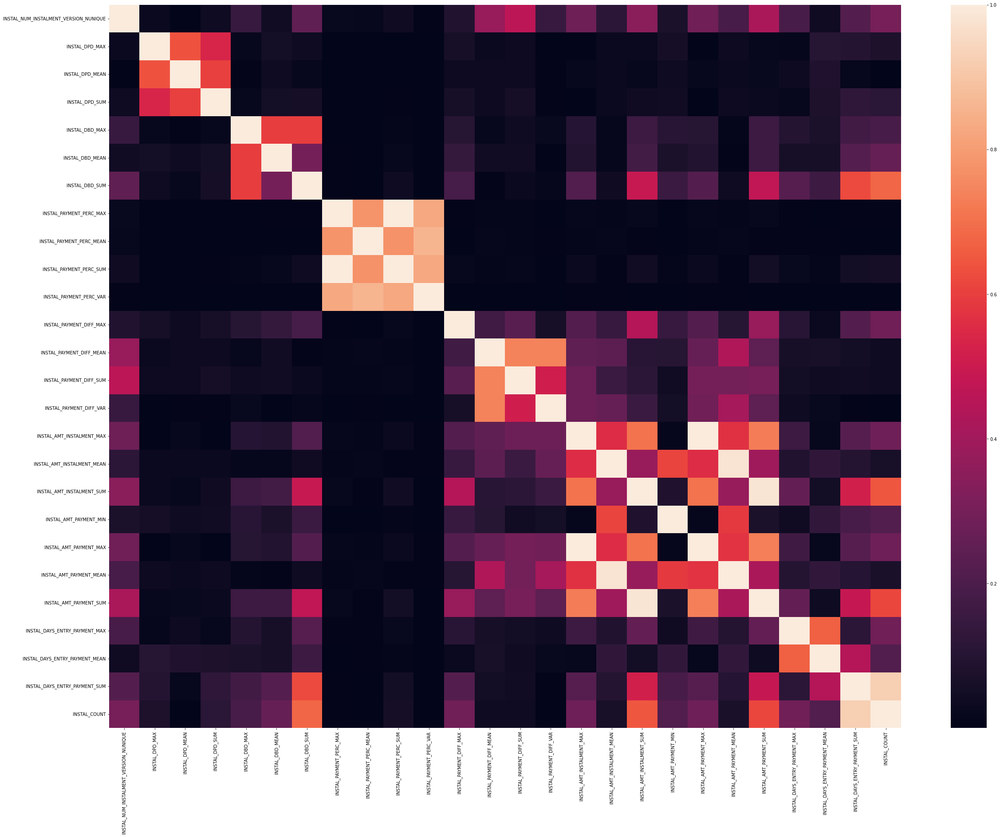

INSTAL_PAYMENT_PERC_MAX INSTAL_PAYMENT_PERC_SUM--------------------------- 0.9972097016606476 
INSTAL_AMT_INSTALMENT_MAX INSTAL_AMT_PAYMENT_MAX---------------------------- 0.9992372700745243 
INSTAL_AMT_INSTALMENT_MEAN INSTAL_AMT_PAYMENT_MEAN--------------------------- 0.97939558525372 
INSTAL_AMT_INSTALMENT_SUM INSTAL_AMT_PAYMENT_SUM---------------------------- 0.9817797151449309 
INSTAL_DAYS_ENTRY_PAYMENT_SUM INSTAL_COUNT-------------------------------------- -0.9221487405766008 


In [74]:
corr_col = exploratory_data(ins_agg)

### Target feature analysis

In [75]:
df = df.join(ins_agg, how='left', on='SK_ID_CURR')
ins_col = ins_agg.columns

In [78]:
# Evaluation using ANOVA if their is a relationship between a features and the target
#ANOVA for TARGET
import scipy.stats as stats

dv = 'TARGET'
ivs = ins_col
print('TARGET')
result = []

for iv in ivs:
# Create dataset for each TARGET
    target_value = df.groupby(dv)[iv]
    datasets = {}
    for groups, data in target_value:
        datasets[groups] = data
    
    fvalue, pvalue = stats.f_oneway(datasets[0].dropna(),
                                    datasets[1].dropna())
    result.append([iv,
                   fvalue,
                   pvalue])
    
    #print(f' {iv :_<50} {fvalue :_<20} {pvalue}')

TARGET


/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3661: RuntimeWarning: invalid value encountered in subtract
  alldata -= offset
/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3669: RuntimeWarning: invalid value encountered in subtract
  ssbn += _square_of_sums(a - offset, axis=axis) / a.shape[axis]


In [79]:
# Select the 20 lowest pvalue
display(pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20])
interest_col = pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20]['features']

,features,fvalue,pvalue
23,INSTAL_DAYS_ENTRY_PAYMENT_MEAN,565.496589,7.051118e-125
24,INSTAL_DAYS_ENTRY_PAYMENT_SUM,362.355500,9.678223e-81
6,INSTAL_DBD_SUM,317.020162,7.040568e-71
12,INSTAL_PAYMENT_DIFF_MEAN,251.249164,1.464833e-56
13,INSTAL_PAYMENT_DIFF_SUM,217.937850,2.654825e-49
18,INSTAL_AMT_PAYMENT_MIN,193.114744,6.862770e-44
21,INSTAL_AMT_PAYMENT_SUM,173.383555,1.385229e-39
20,INSTAL_AMT_PAYMENT_MEAN,156.631681,6.293319e-36
5,INSTAL_DBD_MEAN,131.308865,2.151310e-30
25,INSTAL_COUNT,129.854011,4.475708e-30


### Feature engineering

In [80]:
# Remove features (EDA)
rm = []

# remove correlated features
for col in corr_col:
    rm.append(col)

df.drop(rm, axis=1, inplace=True)

## Credit card balance

In [84]:
# CC balance aggregation

cc = pd.read_csv('data/credit_card_balance.csv')
cc, cat_cols = one_hot_encoder(cc, nan_as_category= True)
# General aggregations
cc.drop(['SK_ID_PREV'], axis= 1, inplace = True)
cc_agg = cc.groupby('SK_ID_CURR').agg(['min', 'max', 'mean', 'sum', 'var'])
cc_agg.columns = pd.Index(['CC_' + e[0] + "_" + e[1].upper() for e in cc_agg.columns.tolist()])
# Count credit card lines
cc_agg['CC_COUNT'] = cc.groupby('SK_ID_CURR').size()
del cc
gc.collect()

1723

### Shape and feature engineering

Shape analysis
(103558, 141)
float64    101
uint8       24
int64       16
dtype: int64


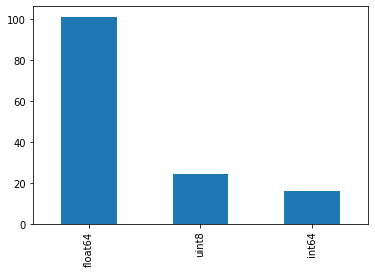

Missing values


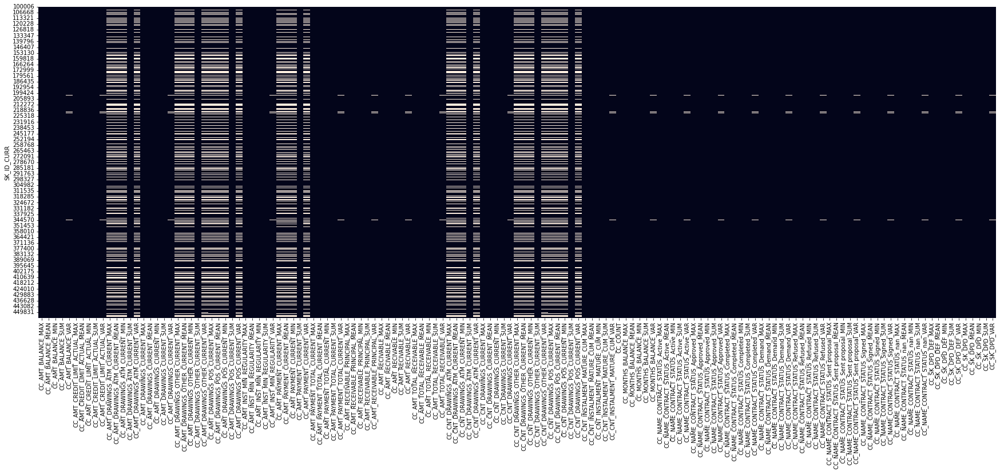

,column_name,missing_count,filling_factor
0,CC_AMT_PAYMENT_CURRENT_VAR,31956,69.141930
1,CC_AMT_DRAWINGS_POS_CURRENT_VAR,31866,69.228838
2,CC_AMT_DRAWINGS_OTHER_CURRENT_VAR,31866,69.228838
3,CC_CNT_DRAWINGS_ATM_CURRENT_VAR,31866,69.228838
4,CC_CNT_DRAWINGS_OTHER_CURRENT_VAR,31866,69.228838
5,CC_AMT_DRAWINGS_ATM_CURRENT_VAR,31866,69.228838
6,CC_CNT_DRAWINGS_POS_CURRENT_VAR,31866,69.228838
7,CC_AMT_PAYMENT_CURRENT_MIN,31438,69.642133
8,CC_AMT_PAYMENT_CURRENT_MEAN,31438,69.642133
9,CC_AMT_PAYMENT_CURRENT_MAX,31438,69.642133


-------------------------------------------------
Univariate Analysis
-------------------------------------------------
Features/features relationship


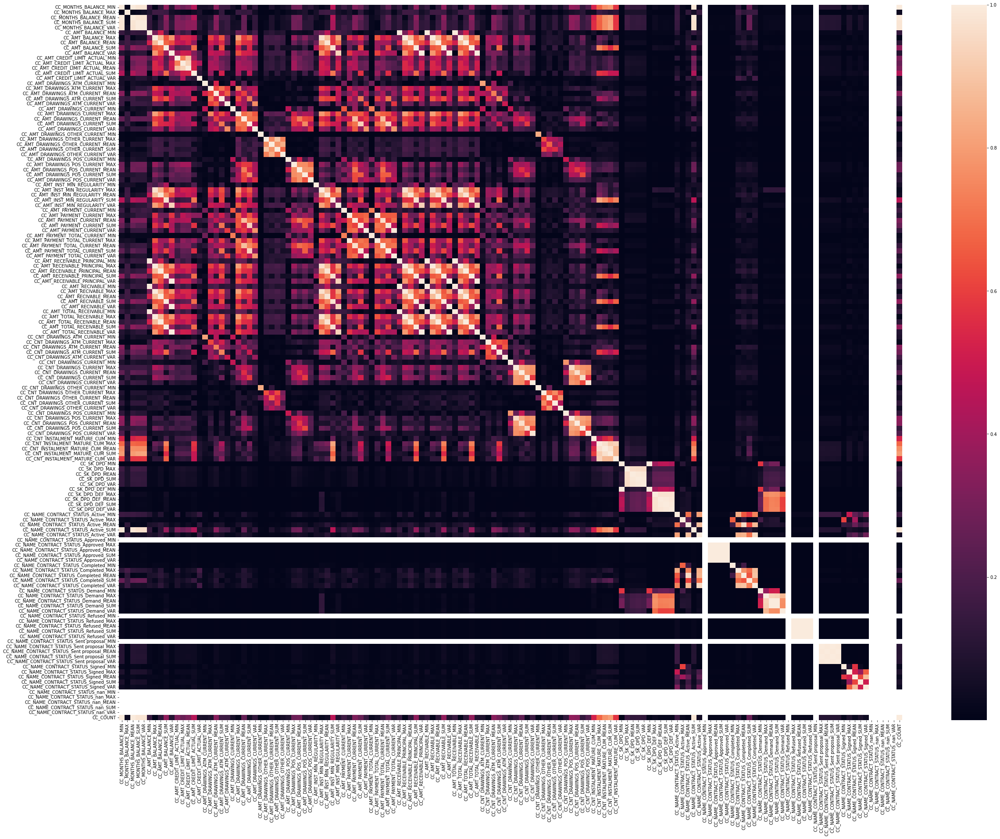

CC_MONTHS_BALANCE_MIN CC_MONTHS_BALANCE_MEAN---------------------------- 0.9995928671623391 
CC_MONTHS_BALANCE_MIN CC_MONTHS_BALANCE_SUM----------------------------- 0.9820482174708104 
CC_MONTHS_BALANCE_MIN CC_MONTHS_BALANCE_VAR----------------------------- -0.9815478696557094 
CC_MONTHS_BALANCE_MIN CC_NAME_CONTRACT_STATUS_Active_SUM---------------- -0.9890523812061148 
CC_MONTHS_BALANCE_MIN CC_COUNT------------------------------------------ -0.9992657744299548 
CC_MONTHS_BALANCE_MEAN CC_MONTHS_BALANCE_SUM----------------------------- 0.9811301880631677 
CC_MONTHS_BALANCE_MEAN CC_MONTHS_BALANCE_VAR----------------------------- -0.9801203859113194 
CC_MONTHS_BALANCE_MEAN CC_NAME_CONTRACT_STATUS_Active_SUM---------------- -0.9879155904635292 
CC_MONTHS_BALANCE_MEAN CC_COUNT------------------------------------------ -0.9978682251274865 
CC_MONTHS_BALANCE_SUM CC_MONTHS_BALANCE_VAR----------------------------- -0.9995997293302031 
CC_MONTHS_BALANCE_SUM CC_NAME_CONTRACT_STATUS_Active_SUM---

In [85]:
corr_col = exploratory_data(cc_agg)

### Target features analysis

In [86]:
df = df.join(cc_agg, how='left', on='SK_ID_CURR')
cc_col = cc_agg.columns

In [87]:
# Evaluation using ANOVA if their is a relationship between a features and the target
#ANOVA for TARGET
import scipy.stats as stats

dv = 'TARGET'
ivs = cc_col
print('TARGET')
result = []

for iv in ivs:
# Create dataset for each TARGET
    target_value = df.groupby(dv)[iv]
    datasets = {}
    for groups, data in target_value:
        datasets[groups] = data
    
    fvalue, pvalue = stats.f_oneway(datasets[0].dropna(),
                                    datasets[1].dropna())
    result.append([iv,
                   fvalue,
                   pvalue])
    
    print(f' {iv :_<50} {fvalue :_<20} {pvalue}')

TARGET
 CC_MONTHS_BALANCE_MIN_____________________________ 328.4174637029708___ 2.902029231239232e-73
 CC_MONTHS_BALANCE_MAX_____________________________ 55.44751283739301___ 9.687108092950186e-14
 CC_MONTHS_BALANCE_MEAN____________________________ 336.2274672478______ 5.86391804353775e-75
 CC_MONTHS_BALANCE_SUM_____________________________ 304.0958217351321___ 5.514069429463246e-68
 CC_MONTHS_BALANCE_VAR_____________________________ 299.48667958031973__ 5.5332079840726906e-67
 CC_AMT_BALANCE_MIN________________________________ 359.2502156550975___ 5.950362492707524e-80
 CC_AMT_BALANCE_MAX________________________________ 413.2793937241822___ 1.158883717566853e-91
 CC_AMT_BALANCE_MEAN_______________________________ 665.5090959965595___ 3.37631000671818e-146
 CC_AMT_BALANCE_SUM________________________________ 30.280431956519877__ 3.749305551928758e-08
 CC_AMT_BALANCE_VAR________________________________ 132.89566722939963__ 1.003658168143884e-30
 CC_AMT_CREDIT_LIMIT_ACTUAL_MIN____________

/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())


 CC_SK_DPD_MEAN____________________________________ 0.8870017037876968__ 0.3462937311115495
 CC_SK_DPD_SUM_____________________________________ 1.1054059543838612__ 0.2930857003010598
 CC_SK_DPD_VAR_____________________________________ 0.9947767857286723__ 0.3185804795962306
 CC_SK_DPD_DEF_MIN_________________________________ nan_________________ nan
 CC_SK_DPD_DEF_MAX_________________________________ 4.367499850390555___ 0.03663359914676303
 CC_SK_DPD_DEF_MEAN________________________________ 3.8548748910185084__ 0.04960480982437876


/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())


 CC_SK_DPD_DEF_SUM_________________________________ 4.224163856801435___ 0.03985523199091294
 CC_SK_DPD_DEF_VAR_________________________________ 4.175988768678679___ 0.041003663037898354
 CC_NAME_CONTRACT_STATUS_Active_MIN________________ 61.77870215660247___ 3.8868649524268565e-15
 CC_NAME_CONTRACT_STATUS_Active_MAX________________ 0.12328012078351544_ 0.7255046595276375
 CC_NAME_CONTRACT_STATUS_Active_MEAN_______________ 34.4279769948495____ 4.4391664614790155e-09
 CC_NAME_CONTRACT_STATUS_Active_SUM________________ 307.4577039029344___ 1.0271756603209981e-68
 CC_NAME_CONTRACT_STATUS_Active_VAR________________ 34.389004063798815__ 4.529034923342895e-09
 CC_NAME_CONTRACT_STATUS_Approved_MIN______________ nan_________________ nan
 CC_NAME_CONTRACT_STATUS_Approved_MAX______________ 0.47462557110535686_ 0.4908686899652913
 CC_NAME_CONTRACT_STATUS_Approved_MEAN_____________ 0.4736178002449769__ 0.49132933953230773
 CC_NAME_CONTRACT_STATUS_Approved_SUM______________ 0.47462557110535686_ 0.4

/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())


 CC_NAME_CONTRACT_STATUS_Approved_VAR______________ 0.4727714497936984__ 0.4917167759551683
 CC_NAME_CONTRACT_STATUS_Completed_MIN_____________ 2.5636887302414557__ 0.10934682265281669
 CC_NAME_CONTRACT_STATUS_Completed_MAX_____________ 49.829167897263424__ 1.6898175787709033e-12
 CC_NAME_CONTRACT_STATUS_Completed_MEAN____________ 39.49839104861823___ 3.298804268224675e-10
 CC_NAME_CONTRACT_STATUS_Completed_SUM_____________ 36.08530721958715___ 1.8961305549946033e-09
 CC_NAME_CONTRACT_STATUS_Completed_VAR_____________ 36.67513096717______ 1.4012264059013429e-09
 CC_NAME_CONTRACT_STATUS_Demand_MIN________________ nan_________________ nan
 CC_NAME_CONTRACT_STATUS_Demand_MAX________________ 0.4121881132265458__ 0.5208626831924645
 CC_NAME_CONTRACT_STATUS_Demand_MEAN_______________ 1.3962323387019173__ 0.23735865331685263
 CC_NAME_CONTRACT_STATUS_Demand_SUM________________ 1.9897855573635765__ 0.15836688242021296
 CC_NAME_CONTRACT_STATUS_Demand_VAR________________ 0.06464519402736589_ 0.79

/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())
/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())


 CC_NAME_CONTRACT_STATUS_Refused_MIN_______________ nan_________________ nan
 CC_NAME_CONTRACT_STATUS_Refused_MAX_______________ 0.557854505013579___ 0.45512800969107137
 CC_NAME_CONTRACT_STATUS_Refused_MEAN______________ 0.34305576511496644_ 0.5580721857600652
 CC_NAME_CONTRACT_STATUS_Refused_SUM_______________ 0.557854505013579___ 0.45512800969107137
 CC_NAME_CONTRACT_STATUS_Refused_VAR_______________ 0.3457699426612829__ 0.5565190253039352


/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())


 CC_NAME_CONTRACT_STATUS_Sent proposal_MIN_________ nan_________________ nan
 CC_NAME_CONTRACT_STATUS_Sent proposal_MAX_________ 13.214166090832796__ 0.0002780013234810318
 CC_NAME_CONTRACT_STATUS_Sent proposal_MEAN________ 13.639204286756481__ 0.00022164685129366155
 CC_NAME_CONTRACT_STATUS_Sent proposal_SUM_________ 13.214166090832796__ 0.0002780013234810318
 CC_NAME_CONTRACT_STATUS_Sent proposal_VAR_________ 13.580605831645574__ 0.00022867421421136932
 CC_NAME_CONTRACT_STATUS_Signed_MIN________________ 1.9561464933808337__ 0.16192961294473662
 CC_NAME_CONTRACT_STATUS_Signed_MAX________________ 6.83908480718883____ 0.00891999191562656
 CC_NAME_CONTRACT_STATUS_Signed_MEAN_______________ 0.028206520363282608 0.8666246029008292
 CC_NAME_CONTRACT_STATUS_Signed_SUM________________ 3.3413985421951935__ 0.06756059183978927
 CC_NAME_CONTRACT_STATUS_Signed_VAR________________ 0.22444182286266937_ 0.6356773146707844
 CC_NAME_CONTRACT_STATUS_nan_MIN___________________ nan_________________ nan
 

/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())
/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())
/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined or infinite
  warnings.warn(F_onewayConstantInputWarning())
/Users/franck/opt/anaconda3/envs/datascience_devenv/lib/python3.9/site-packages/scipy/stats/stats.py:3650: F_onewayConstantInputWarning: Each of the input arrays is constant;the F statistic is not defined 

In [88]:
# Select the 20 lowest pvalue
display(pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20])
interest_col = pd.DataFrame(result, columns=['features', 'fvalue', 'pvalue']).sort_values(by=['pvalue'])[:20]['features']

,features,fvalue,pvalue
71,CC_CNT_DRAWINGS_CURRENT_MAX,902.624200,2.719550e-197
67,CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,717.378369,4.037353e-157
7,CC_AMT_BALANCE_MEAN,665.509096,3.376310e-146
62,CC_AMT_TOTAL_RECEIVABLE_MEAN,654.977663,6.331370e-144
57,CC_AMT_RECIVABLE_MEAN,654.789230,6.952985e-144
52,CC_AMT_RECEIVABLE_PRINCIPAL_MEAN,648.470397,1.607533e-142
72,CC_CNT_DRAWINGS_CURRENT_MEAN,595.829782,3.748578e-131
37,CC_AMT_INST_MIN_REGULARITY_MEAN,474.919612,5.214220e-105
6,CC_AMT_BALANCE_MAX,413.279394,1.158884e-91
61,CC_AMT_TOTAL_RECEIVABLE_MAX,404.677301,8.467105e-90


### Feature engineering

In [89]:
# Remove features (EDA)
rm = []

idx_filling = filling_factor(cc_agg)[filling_factor(cc_agg)['filling_factor'] < 60]
idx_filling

# remove col with less than 60% filling unless it is correlated to TARGET
for col in prev_agg:
    if col in idx_filling['column_name'].to_list():
        rm.append(col)

for col in rm:
    if col in interest_col.tolist(): 
        rm.remove(col)

# remove correlated features
for col in corr_col:
    rm.append(col)

df.drop(rm, axis=1, inplace=True)

## Final dataset visualisation

In [90]:
df.shape

(307511, 433)

In [91]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,FLOORSMAX_AVG,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_3,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_PERC,INCOME_CREDIT_PERC,INCOME_PER_PERSON,ANNUITY_INCOME_PERC,PAYMENT_RATE,BURO_DAYS_CREDIT_MIN,BURO_DAYS_CREDIT_MAX,BURO_DAYS_CREDIT_MEAN,BURO_DAYS_CREDIT_VAR,BURO_DAYS_CREDIT_ENDDATE_MIN,BURO_DAYS_CREDIT_ENDDATE_MAX,BURO_DAYS_CREDIT_ENDDATE_MEAN,BURO_DAYS_CREDIT_UPDATE_MEAN,BURO_CREDIT_DAY_OVERDUE_MAX,BURO_CREDIT_DAY_OVERDUE_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,BURO_AMT_CREDIT_SUM_MAX,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_SUM_SUM,BURO_AMT_CREDIT_SUM_DEBT_MAX,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_OVERDUE_MEAN,BURO_AMT_CREDIT_SUM_LIMIT_MEAN,BURO_AMT_CREDIT_SUM_LIMIT_SUM,BURO_CNT_CREDIT_PROLONG_SUM,BURO_MONTHS_BALANCE_SIZE_MEAN,BURO_MONTHS_BALANCE_SIZE_SUM,BURO_CREDIT_ACTIVE_Active_MEAN,BURO_CREDIT_ACTIVE_Bad debt_MEAN,BURO_CREDIT_ACTIVE_Sold_MEAN,BURO_CREDIT_CURRENCY_currency 1_MEAN,BURO_CREDIT_CURRENCY_currency 3_MEAN,BURO_CREDIT_CURRENCY_currency 4_MEAN,BURO_CREDIT_TYPE_Another type of loan_MEAN,BURO_CREDIT_TYPE_Car loan_MEAN,BURO_CREDIT_TYPE_Cash loan (non-earmarked)_MEAN,BURO_CREDIT_TYPE_Consumer credit_MEAN,BURO_CREDIT_TYPE_Credit card_MEAN,BURO_CREDIT_TYPE_Interbank credit_MEAN,BURO_CREDIT_TYPE_Loan for business development_MEAN,BURO_CREDIT_TYPE_Loan for purchase of shares (margin lending)_MEAN,BURO_CREDIT_TYPE_Loan for the purchase of equipment_MEAN,BURO_CREDIT_TYPE_Loan for working capital replenishment_MEAN,BURO_CREDIT_TYPE_Microloan_MEAN,...,INSTAL_DBD_MAX,INSTAL_DBD_MEAN,INSTAL_DBD_SUM,INSTAL_PAYMENT_PERC_MAX,INSTAL_PAYMENT_PERC_MEAN,INSTAL_PAYMENT_PERC_VAR,INSTAL_PAYMENT_DIFF_MAX,INSTAL_PAYMENT_DIFF_MEAN,INSTAL_PAYMENT_DIFF_SUM,INSTAL_PAYMENT_DIFF_VAR,INSTAL_AMT_INSTALMENT_MAX,INSTAL_AMT_INSTALMENT_MEAN,INSTAL_AMT_INSTALMENT_SUM,INSTAL_AMT_PAYMENT_MIN,INSTAL_DAYS_ENTRY_PAYMENT_MAX,INSTAL_DAYS_ENTRY_PAYMENT_MEAN,INSTAL_DAYS_ENTRY_PAYMENT_SUM,CC_MONTHS_BALANCE_MIN,CC_MONTHS_BALANCE_MAX,CC_AMT_BALANCE_MIN,CC_AMT_BALANCE_MAX,CC_AMT_BALANCE_MEAN,CC_AMT_BALANCE_SUM,CC_AMT_BALANCE_VAR,CC_AMT_CREDIT_LIMIT_ACTUAL_MIN,CC_AMT_CREDIT_LIMIT_ACTUAL_MAX,CC_AMT_CREDIT_LIMIT_ACTUAL_SUM,CC_AMT_CREDIT_LIMIT_ACTUAL_VAR,CC_AMT_DRAWINGS_ATM_CURRENT_MIN,CC_AMT_DRAWINGS_ATM_CURRENT_MAX,CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,CC_AMT_DRAWINGS_ATM_CURRENT_SUM,CC_AMT_DRAWINGS_ATM_CURRENT_VAR,CC_AMT_DRAWINGS_CURRENT_MIN,CC_AMT_DRAWINGS_CURRENT_MAX,CC_AMT_DRAWINGS_CURRENT_MEAN,CC_AMT_DRAWINGS_CURRENT_SUM,CC_AMT_DRAWINGS_CURRENT_VAR,CC_AMT_DRAWINGS_OTHER_CURRENT_MIN,CC_AMT_DRAWINGS_OTHER_CURRENT_MAX,CC_AMT_DRAWINGS_OTHER_CURRENT_MEAN,CC_AMT_DRAWINGS_OTHER_CURRENT_VAR,CC_AMT_DRAWINGS_POS_CURRENT_MIN,CC_AMT_DRAWINGS_POS_CURRENT_MAX,CC_AMT_DRAWINGS_POS_CURRENT_MEAN,CC_AMT_DRAWINGS_POS_CURRENT_SUM,CC_AMT_DRAWINGS_POS_CURRENT_VAR,CC_AMT_INST_MIN_REGULARITY_MIN,CC_AMT_PAYMENT_CURRENT_MIN,CC_AMT_PAYMENT_CURRENT_MAX,CC_AMT_PAYMENT_CURRENT_MEAN,CC_AMT_PAYMENT_CURRENT_VAR,CC_AMT_PAYMENT_TOTAL_CURRENT_MIN,CC_CNT_DRAWINGS_ATM_CURRENT_MIN,CC_CNT_DRAWINGS_ATM_CURRENT_MAX,CC_CNT_DRAWINGS_ATM_CURRENT_

float64    400
int64       24
object       9
dtype: int64


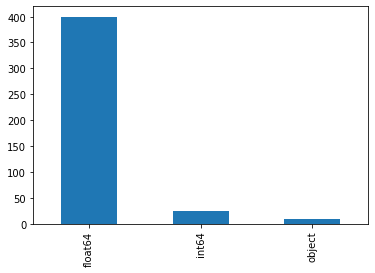

In [92]:
# Count features type
print(df.dtypes.value_counts())

#Show feautres type count
df.dtypes.value_counts().plot.bar()
plt.show()

In [93]:
# Calculated the total percentage of missing values

print(df.isna().sum().sum()/(df.shape[0]*df.shape[1])*100)

21.66595396129317


In [94]:
df.to_csv('data/model_dataset.csv', index=False)